# Análisis Exploratorio de Datos — Muestra analítica del Distrito Centro (v5 · ventana ≤ 6 meses)
### Tesis de Maestría · Modelo de Valuación Automática (AVM) · Rosario

Este cuaderno documenta el análisis exploratorio de la muestra analítica sobre la que se
construirá el modelo de valuación de departamentos del Distrito Centro de Rosario. El objetivo
no es todavía modelar, sino **entender el fenómeno**: cómo se distribuyen los precios de
publicación, qué estructura tienen las variables estructurales y territoriales, dónde aparecen
faltantes y valores atípicos, y qué patrones espaciales anticipan el rol de la localización.

Cada sección combina tres elementos: el **método** (la fórmula que respalda cada cálculo), la
**evidencia** (tablas y gráficos) y una **lectura** que interpreta lo observado y anticipa las
decisiones del preprocesamiento. Trabajamos con precios de **publicación** (no de cierre) y, de
manera deliberada, **no imputamos faltantes ni recortamos outliers**: los describimos y los
marcamos, dejando esas decisiones para la etapa siguiente del pipeline.

### Entorno y dependencias

El cuaderno usa las librerías científicas estándar de Python más **`scipy`** (diagnósticos de normalidad:
Q-Q plot y curtosis, §4). Todos los gráficos —incluido el mapa de barrios— son **estáticos**
(matplotlib), de modo que el notebook se renderiza completo en GitHub/nbviewer sin ejecutar nada.
Para instalar todo:

```
pip install pandas numpy scipy matplotlib seaborn
```

## 1. El dataset: origen, construcción y alcance

Los datos provienen de un **relevamiento propio de avisos de venta de departamentos** publicados
en ZonaProp para el Distrito Centro de Rosario. La captura se realizó con un scraper desarrollado
para esta tesis, que recorre el listado por bandas de precio (para superar el tope de paginación
del portal) y luego visita la página de detalle de cada aviso para recuperar dirección,
coordenadas, descripción y atributos estructurales.

Sobre esa base cruda se aplicó un proceso de **auditoría y depuración por etapas**, trazado con
manifiestos (hash, dimensiones y registros de exclusión en cada paso):

1. **Identidad de propiedad.** Cada aviso (`posting_id`) se vincula a una propiedad física
   (`property_id`) y a un agrupamiento por edificio/cuadra (`building_cluster_id`). Esto permite
   detectar **republicaciones** —una misma unidad reavisada, a veces con otro precio— y evitar,
   más adelante, la fuga de información entre entrenamiento y prueba. La necesidad de identificar
   republicaciones en antecedentes argentinos basados en avisos la señalan **Gutiérrez et al. (2026)**.
2. **Validación geoespacial con cartografía oficial.** Las coordenadas se validaron contra la
   cartografía oficial de la **Municipalidad de Rosario**, publicada en su **Portal de Datos Abiertos**
   (conjuntos *Distritos Descentralizados* y *Barrios*), en coordenadas geográficas **WGS 84
   (EPSG:4326)**. A cada propiedad se le asignó el **barrio oficial** por cruce *point-in-polygon*
   y un **nivel de calidad geográfica** (`geo_nivel_calidad`) que distingue coordenadas dentro del
   polígono, coordenadas compartidas sospechosas y direcciones validadas por Georef. Registrar esa
   calidad como variable de auditoría sigue la propuesta de `geolocation_quality` de
   **Gyger et al. (2026)**.
3. **Auditoría del target y de las variables.** Se auditaron precio, superficie, baños,
   antigüedad y expensas, conservando siempre las columnas originales y agregando versiones
   auditadas (`*_auditado`) y una muestra analítica final marcada como apta para EDA.

El resultado de esa depuración es la versión **v4** (9.498 avisos). Sobre ella se aplica un último
criterio de **definición de muestra** que da lugar a la **v5**, descrita a continuación.

### Alcance: qué avisos incluye la muestra

El relevamiento cubre **departamentos en venta** del **Distrito Centro** de Rosario, publicados en
ZonaProp. Comprende tanto avisos de **unidades individuales** (`tipo_operacion = PROPERTY`, la gran
mayoría) como de **emprendimientos/desarrollos** (`DEVELOPMENT`), y abarca tipologías de **1 a "5 o
más" ambientes** (el scraper recorrió esas cinco bandas; en los datos aparecen hasta ~12 ambientes en
la banda de 5+). La operación es siempre **venta** y el precio se toma en **dólares**, la moneda de
referencia del mercado inmobiliario argentino.

### Ventana temporal: por qué ≤ 6 meses

La captura fue un **corte transversal** tomado entre el **15 y el 17 de agosto de 2026**
(`first_seen`/`last_seen`); no es un panel longitudinal. Ahora bien, cada aviso tiene su propia
**fecha de publicación** (`datePosted`), recuperada desde la base del scraper (cobertura 98,5 %), y
la **antigüedad del aviso** (captura − publicación) resultó muy dispersa: la mediana ronda los 6
meses, pero había avisos de hasta 2016.

Esto es un problema para un AVM: aunque el precio esté en dólares, **un aviso antiguo refleja el
mercado de su época, no el actual**, y mezclar épocas contamina el target con la inflación de costos
de construcción y la deriva del mercado. Al medir el precio/m² por antigüedad —incluso dentro de
segmentos homogéneos (mismo barrio, ambientes y superficie)— se observa que **hasta los 6 meses el
nivel de precios es plano, y a partir de allí aparece una deriva al alza de ~20 %** en unidades
comparables. Es el fenómeno de los *listings rancios sobrevaluados*: las unidades que no se venden
permanecen publicadas justamente porque están por encima del mercado.

Por eso la muestra analítica se restringe a los avisos con **antigüedad de publicación ≤ 6 meses**
(se excluyen los ~1,5 % sin fecha, porque no puede verificarse su recencia). El resultado es la
**v5**, con la que trabaja este cuaderno; el criterio, su evidencia y el filtro quedan documentados y
son reproducibles (`scripts/preprocessing/definir_muestra_temporal.py`). La v5 **no** define todavía
los folds ni el universo final de modelado: es la base depurada y temporalmente homogénea para
explorar y decidir el preprocesamiento.

In [1]:
# ── Configuración y carga ─────────────────────────────────────────────────
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")

# raíz del repo (robusto ante el cwd de VS Code)
ROOT = Path.cwd()
while not (ROOT / "data" / "processed").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

sns.set_theme(style="whitegrid", context="notebook")
PAL, PAL2, ACCENT = "#2c6e91", "#c0562b", "#3a8f5e"
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 130, "savefig.bbox": "tight",
                     "font.size": 11, "axes.titleweight": "bold", "axes.titlesize": 12.5,
                     "axes.labelsize": 10.5, "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
                     "figure.autolayout": True})

df = pd.read_csv(ROOT / "data" / "processed" / "zonaprop_v2_eda_centro_v5.csv.gz")
num = lambda c: pd.to_numeric(df[c], errors="coerce")
def skew(s):
    # Coeficiente de asimetría de Fisher-Pearson (g1), tercer momento estandarizado.
    # g1 = m3 / m2**1.5, con m_k = (1/n) * sum((x - x_bar)**k). Sin dependencia de scipy.
    s = pd.to_numeric(s, errors="coerce").dropna().to_numpy(); n = len(s)
    if n < 3: return np.nan
    d = s - s.mean()
    return (np.sum(d**3) / n) / (np.sum(d**2) / n) ** 1.5
def spearman(a, b):
    # Rho de Spearman = correlación de Pearson sobre los rangos. Sin dependencia de scipy
    # (pandas usa scipy si se pide corr(method="spearman"); acá lo evitamos con .rank()).
    a = pd.to_numeric(a, errors="coerce"); b = pd.to_numeric(b, errors="coerce")
    m = a.notna() & b.notna()
    if m.sum() < 3: return np.nan
    return a[m].rank().corr(b[m].rank())
def money(x, _=None): return f"${x/1e6:.1f}M" if abs(x) >= 1e6 else f"${x/1e3:.0f}k"
def kfmt(x, _=None):  return f"{x/1e6:.1f}M" if abs(x) >= 1e6 else f"{x/1e3:.0f}k"
usd = lambda x: f"${x:,.0f}"
def etiqueta(v):
    if pd.isna(v): return "NA"
    try:
        f = float(v); return str(int(f)) if f.is_integer() else str(v)
    except (TypeError, ValueError): return str(v)

print(f"Muestra analítica v4: {len(df):,} avisos · {df.shape[1]} columnas")
df[["property_id", "barrio_oficial_geo", "eda_precio_usd", "eda_superficie_total_m2", "ambientes"]].head()

Muestra analítica v4: 4,765 avisos · 124 columnas


,property_id,barrio_oficial_geo,eda_precio_usd,eda_superficie_total_m2,ambientes
0,prop_6ad1ca5d1353b7a7,ALBERTO OLMEDO,73945.0,45.0,1
1,prop_ceb3a1dff3182a0d,CENTRO,40000.0,27.0,1
2,prop_940ad34ada7cd4b4,ECHESORTU,65000.0,27.0,1
3,prop_b85e296b5997fa55,REPUBLICA DE LA 6TA,31000.0,30.0,1
4,prop_eccb9510a1780f7d,LUIS AGOTE,35900.0,27.0,1


### Variables principales

| Grupo | Variables | Rol |
|---|---|---|
| **Identidad / trazabilidad** | `property_id`, `building_cluster_id`, `posting_id_ultimo`, `n_capturas`, `cambios_precio` | Deduplicación, republicaciones, historial |
| **Target** | `eda_precio_usd`, `eda_precio_m2` | Precio de publicación (USD) y valor unitario |
| **Estructurales** | `ambientes`, `dormitorios`, `eda_banos`, `eda_cocheras`, `eda_superficie_total_m2`, `eda_superficie_cubierta_m2`, `antiguedad`, `eda_expensas` | Atributos físicos del inmueble |
| **Localización** | `eda_latitud`, `eda_longitud`, `barrio_oficial_geo`, `geo_nivel_calidad`, `apto_eda_espacial_v4` | Coordenadas y barrio oficial validados |
| **Temporal / captura** | `fecha_publicacion`, `antiguedad_aviso_dias`, `first_seen`, `last_seen`, `n_capturas` | Fecha de publicación, antigüedad del aviso y ventana de captura |
| **Operación / alcance** | `tipo_operacion`, `ambientes` | Individual vs. desarrollo; tipología |
| **Texto (`feat_*`)** | balcón, cochera, amenities, pileta, seguridad, apto crédito, vista al río, … | Atributos extraídos de la descripción |

Las columnas con prefijo `eda_` son las versiones **auditadas y listas para análisis**; las
originales se conservan sin sobrescribir para trazabilidad.

### Alcance y antigüedad de los avisos en cifras

Las tres vistas siguientes resumen el **alcance** (tipo de operación y tipología por ambientes) y la
**ventana temporal** ya acotada de la muestra v5.

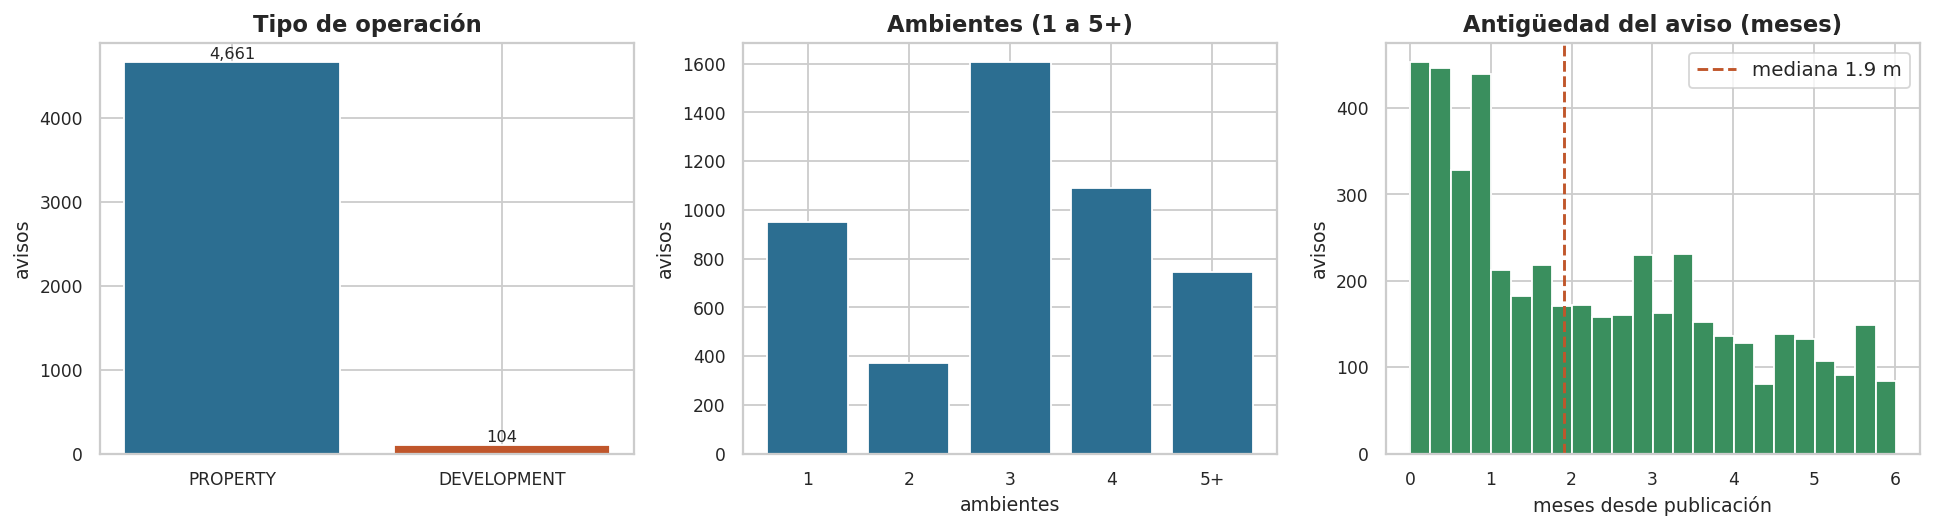

Muestra v5: 4,765 avisos · publicación entre 2026-02-13 y 2026-08-17 · antigüedad mediana 1.9 meses (máx 6.0).


In [2]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))

# tipo de operación
op = df["tipo_operacion"].value_counts()
axs[0].bar(op.index, op.values, color=[PAL, PAL2])
for i, v in enumerate(op.values): axs[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
axs[0].set(title="Tipo de operación", ylabel="avisos")

# tipología por ambientes (1..5+)
amb = df["ambientes"].clip(upper=5)
vc = amb.value_counts().sort_index()
etq = [("5+" if int(k) >= 5 else str(int(k))) for k in vc.index]
axs[1].bar(etq, vc.values, color=PAL)
axs[1].set(title="Ambientes (1 a 5+)", xlabel="ambientes", ylabel="avisos")

# antigüedad del aviso (meses), ya acotada a <= 6
antm = pd.to_numeric(df["antiguedad_aviso_dias"], errors="coerce") / 30.44
axs[2].hist(antm.dropna(), bins=24, color=ACCENT, edgecolor="white")
axs[2].axvline(antm.median(), color=PAL2, ls="--", lw=1.6, label=f"mediana {antm.median():.1f} m")
axs[2].set(title="Antigüedad del aviso (meses)", xlabel="meses desde publicación", ylabel="avisos")
axs[2].legend()
plt.show()

print(f"Muestra v5: {len(df):,} avisos · publicación entre "
      f"{pd.to_datetime(df['fecha_publicacion']).min().date()} y "
      f"{pd.to_datetime(df['fecha_publicacion']).max().date()} · "
      f"antigüedad mediana {antm.median():.1f} meses (máx {antm.max():.1f}).")

La oferta es abrumadoramente de **unidades individuales** en reventa, con una
fracción menor de **emprendimientos**; conviene conservar `tipo_operacion` como variable, porque el
precio de un desarrollo (a estrenar, en pozo) puede comportarse distinto. La tipología confirma el
predominio de departamentos de **3 ambientes**, seguidos por los de 4 y 1. Y la antigüedad del aviso,
**ya acotada a ≤ 6 meses**, garantiza que todos los precios pertenezcan a un mismo régimen temporal de
mercado: es la condición que vuelve comparable el target entre observaciones, requisito implícito de
cualquier modelo hedónico de corte transversal (Rosen, 1974).

## 2. Panorama general y calidad de la muestra

Antes de mirar cada variable conviene dimensionar el conjunto: cuántos avisos hay, qué proporción
es apta para el análisis espacial, cuánta identidad de alta confianza tenemos y cómo se reparte la
calidad de la geolocalización.

,Valor
Métrica,
Avisos (property_id),"4,765"
Aptos análisis espacial,"4,415 (93%)"
Identidad de alta confianza,"4,372 (92%)"
Con republicaciones,270
Con cambios de precio,88
Barrios oficiales,12


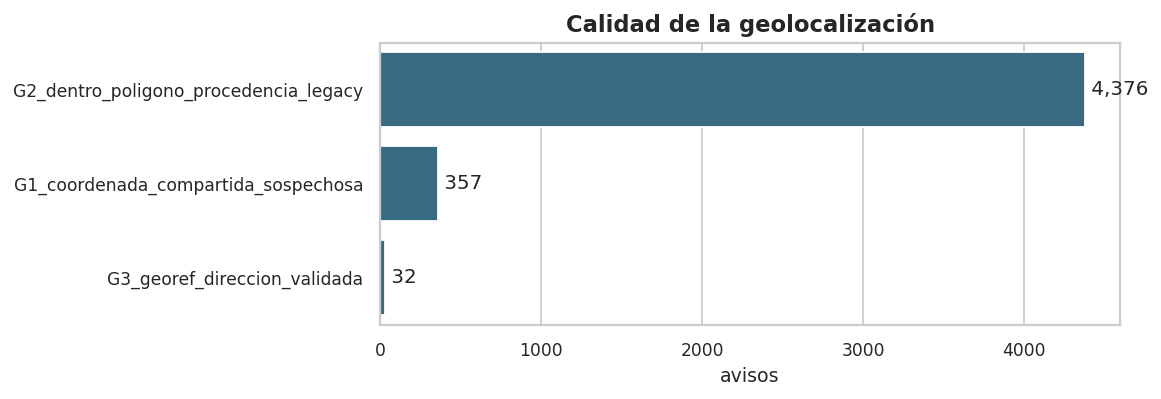

In [3]:
espacial = int(df["apto_eda_espacial_v4"].sum())
conf_alta = int((df["id_confianza"] == "alta").sum())
repub = int((num("n_capturas") > 1).sum())
camb = int((num("cambios_precio") > 0).sum())
resumen = pd.DataFrame({
    "Métrica": ["Avisos (property_id)", "Aptos análisis espacial", "Identidad de alta confianza",
                "Con republicaciones", "Con cambios de precio", "Barrios oficiales"],
    "Valor": [f"{len(df):,}", f"{espacial:,} ({espacial/len(df)*100:.0f}%)",
              f"{conf_alta:,} ({conf_alta/len(df)*100:.0f}%)", f"{repub:,}", f"{camb:,}",
              f"{df['barrio_oficial_geo'].nunique()}"]}).set_index("Métrica")
display(resumen)

vc = df["geo_nivel_calidad"].value_counts()
fig, ax = plt.subplots(figsize=(9, 3.2))
sns.barplot(x=vc.values, y=vc.index, color=PAL, ax=ax)
for i, v in enumerate(vc.values): ax.text(v, i, f" {v:,}", va="center")
ax.set(title="Calidad de la geolocalización", xlabel="avisos", ylabel=""); plt.show()

La muestra reúne **4,765 avisos**, de los cuales alrededor del **93%**
cuenta con coordenadas aptas para el análisis espacial —una cobertura razonable para explorar patrones
territoriales sin sesgos groseros—. La identidad de alta confianza cubre la mayor parte del
conjunto, lo que da respaldo al agrupamiento por propiedad. En cuanto a la calidad geográfica, el
grueso corresponde al nivel **G2** (coordenada dentro del polígono del distrito según la
cartografía oficial); un subconjunto acotado queda en **G1** (coordenada compartida entre varios
avisos, que conviene mirar con cuidado en el análisis espacial fino) y un remanente en **G3**
(dirección validada por el geocodificador oficial). Esta variable no se descarta: se conserva como
**criterio de auditoría y segmentación**. La idea de registrar explícitamente la *calidad de
geolocalización* como variable de auditoría —y de decidir recién después si se usa como predictor o
sólo para segmentar— proviene de **Gyger et al. (2026)**, que proponen un campo `geolocation_quality`
con esa misma lógica. Finalmente, la detección de **republicaciones** (y de cambios de precio entre
capturas) es consistente con que trabajar a nivel de aviso sería engañoso: la unidad de análisis correcta es la
propiedad física, un recaudo que también señala **Gutiérrez et al. (2026)** para antecedentes
argentinos basados en avisos web.

## 3. Distribución territorial: distritos y barrios

La localización es un determinante central del precio inmobiliario, y en Rosario el
**Distrito Centro** agrupa varios barrios oficiales de perfil heterogéneo. El mapa siguiente sitúa
la muestra sobre la **cartografía oficial de la Municipalidad de Rosario**: se dibujan los seis
distritos descentralizados (con el Centro resaltado) y, sobre ellos, los barrios coloreados según
la **cantidad de observaciones** que aporta cada uno. La misma cartografía es la que se usó para
validar las coordenadas y asignar el barrio oficial por cruce *point-in-polygon*, de modo que el
mapa no es solo ilustrativo: refleja la geometría con la que se auditó el dataset.

El mapa es **estático** a propósito: se renderiza en cualquier visor —GitHub y nbviewer incluidos—,
así puede consultarse online sin descargar el repositorio ni ejecutar nada. Cada barrio de la muestra
muestra, de forma fija, su **nombre** y su **cantidad de observaciones**.

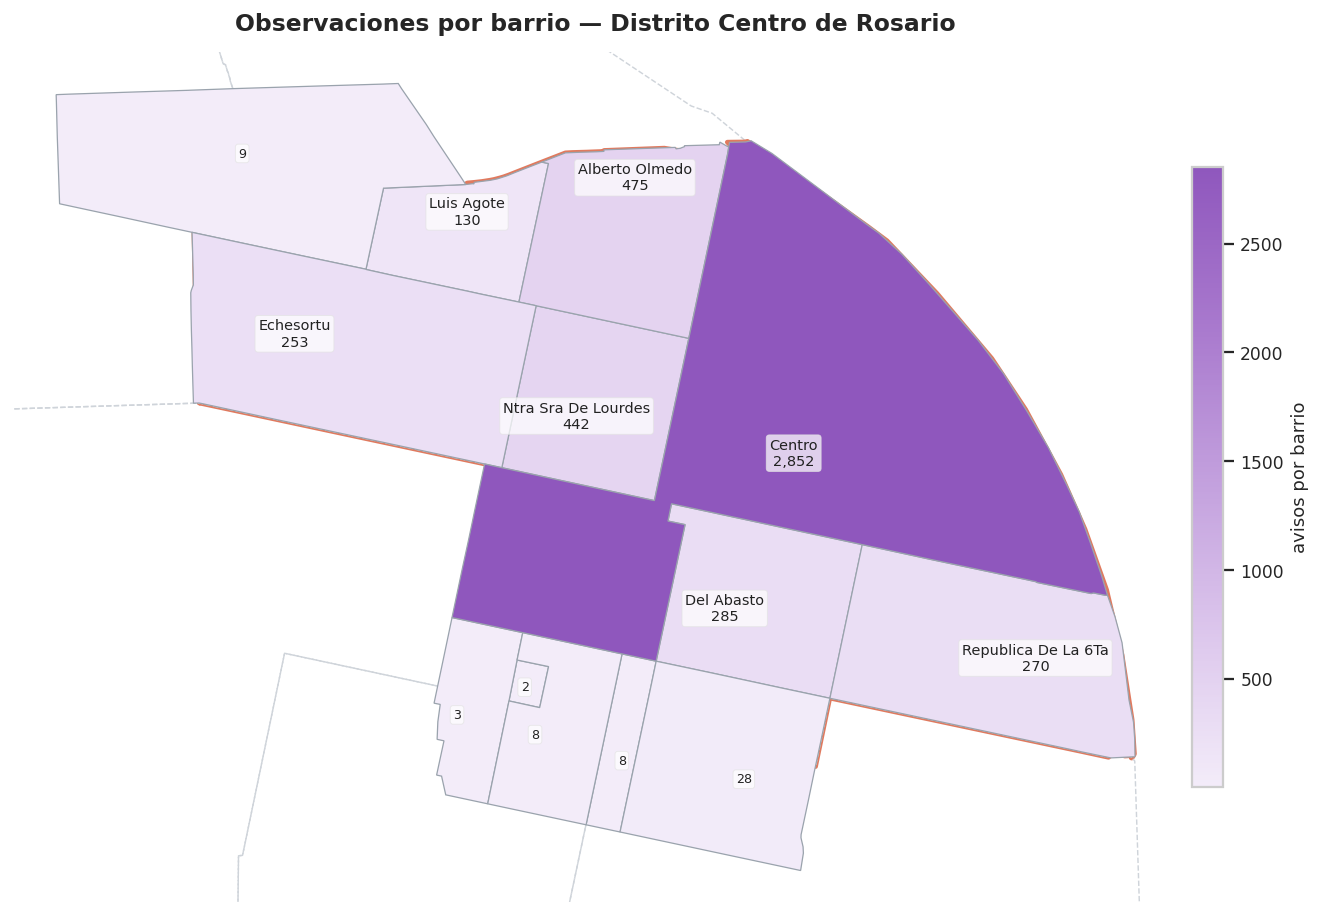

In [4]:
import json
from matplotlib.patches import Polygon as MplPoly
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize, LinearSegmentedColormap

conteo = df.groupby("barrio_oficial_mslink").size().to_dict()
barrios = pd.read_csv(ROOT / "data" / "external" / "barrios_rosario" / "barrios_oficiales.csv")
distritos = pd.read_csv(ROOT / "data" / "external" / "distritos_rosario" / "distritos_descentralizados_rosario.csv")

def anillos(gj):
    g = gj["geometry"]
    if g["type"] == "Polygon": return [g["coordinates"][0]]
    if g["type"] == "MultiPolygon": return [p[0] for p in g["coordinates"]]
    return []

vals = [conteo[int(r["MSLINK"])] for _, r in barrios.iterrows() if int(r["MSLINK"]) in conteo]
norm = Normalize(min(vals), max(vals))
cmap = LinearSegmentedColormap.from_list("pastel", ["#f3ecf9", "#dcc6ec", "#c29fdd", "#a878cd", "#8f57bd"])

fig, ax = plt.subplots(figsize=(11, 9))
xs_all, ys_all = [], []
for _, r in barrios.iterrows():                       # barrios de la muestra: relleno por conteo
    ml = int(r["MSLINK"])
    if ml not in conteo: continue
    n = conteo[ml]; aros = anillos(json.loads(r["GEOJSON"]))
    for ring in aros:
        ax.add_patch(MplPoly(ring, closed=True, facecolor=cmap(norm(n)),
                             edgecolor="#9aa3ad", lw=0.7, zorder=2))
        xs_all += [p[0] for p in ring]; ys_all += [p[1] for p in ring]
    cx = sum(p[0] for p in aros[0]) / len(aros[0]); cy = sum(p[1] for p in aros[0]) / len(aros[0])
    # etiqueta fija: nombre + conteo (nombre solo en los barrios con volumen suficiente)
    etq = f"{str(r['BARRIO']).title()}\n{n:,}" if n >= 100 else f"{n:,}"
    ax.annotate(etq, (cx, cy), ha="center", va="center", fontsize=8 if n >= 100 else 7,
                color="#222", zorder=5, linespacing=1.2,
                bbox=dict(boxstyle="round,pad=0.22", fc="white", ec="#e3e3e3", lw=0.5, alpha=0.72))
for _, r in distritos.iterrows():                     # contorno de distritos (Centro resaltado)
    es_c = r["DISTRITO"] == "CENTRO"
    for ring in anillos(json.loads(r["GEOJSON"])):
        ax.plot([p[0] for p in ring], [p[1] for p in ring], color="#e07a5f" if es_c else "#cfd4da",
                lw=2.6 if es_c else 0.8, ls="-" if es_c else "--", zorder=1)
sm = ScalarMappable(norm=norm, cmap=cmap); sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, shrink=.55, pad=0.01); cbar.set_label("avisos por barrio", fontsize=10)
mx = (max(xs_all) - min(xs_all)) * 0.04; my = (max(ys_all) - min(ys_all)) * 0.04
ax.set_xlim(min(xs_all) - mx, max(xs_all) + mx); ax.set_ylim(min(ys_all) - my, max(ys_all) + my)
ax.set_aspect(1 / np.cos(np.radians(32.95)))
ax.set_title("Observaciones por barrio — Distrito Centro de Rosario", fontsize=13, fontweight="bold", pad=12)
ax.margins(0); ax.set_axis_off()
plt.show()

La muestra está **fuertemente concentrada en el barrio Centro**, que aporta más
de la mitad de los avisos, seguido a distancia por Alberto Olmedo, Nuestra Señora de Lourdes, Del
Abasto, República de la 6ª y Echesortu. Esta concentración es esperable —el Centro es el núcleo de
mayor densidad de oferta— pero tiene una implicancia metodológica: los barrios con pocos registros
deben leerse con cautela en cualquier comparación por barrio, porque sus estadísticas son
inestables. El mapa también deja ver que el recorte "Distrito Centro" de ZonaProp no coincide
exactamente con el polígono administrativo homónimo: abarca barrios que, en la división oficial,
pertenecen a distritos vecinos. Registrar esta diferencia es importante para no confundir el
**alcance del relevamiento** con la **unidad administrativa**.

## 4. La variable objetivo: precio de publicación

El target del modelo es el **precio de publicación en dólares** —no de transacción, distinción que
subrayan **Gutiérrez et al. (2026)** para antecedentes argentinos basados en avisos—. Antes de
decidir en qué escala modelarlo conviene caracterizar su distribución. Reportamos la media, la
mediana y los cuantiles, y medimos la asimetría con el **coeficiente de asimetría muestral de
Fisher-Pearson** ($g_1$), el tercer momento estandarizado:

$$ \bar{x}=\frac{1}{n}\sum_i x_i, \qquad Q_p:\ P(X\le Q_p)=p, \qquad
g_1=\frac{\tfrac{1}{n}\sum_i (x_i-\bar{x})^3}{\left[\tfrac{1}{n}\sum_i (x_i-\bar{x})^2\right]^{3/2}} $$

donde $g_1=0$ indica simetría y $g_1>0$ una cola hacia la derecha. El fundamento de los **momentos
muestrales** y su interpretación está en DeGroot & Schervish (2012) y Casella & Berger (2002); Joanes
& Gill (1998) revisan las distintas estimaciones de $g_1$ (aquí usamos la versión sesgada, equivalente
a `scipy.stats.skew`).
Evaluamos además la transformación $y=\log(1+x)$, habitual para precios porque comprime la cola y
convierte la relación multiplicativa del valor en aproximadamente aditiva; es la escala que emplean,
por ejemplo, **Yazdani (2021)** y **Gyger et al. (2026)** para el precio/renta inmobiliaria.

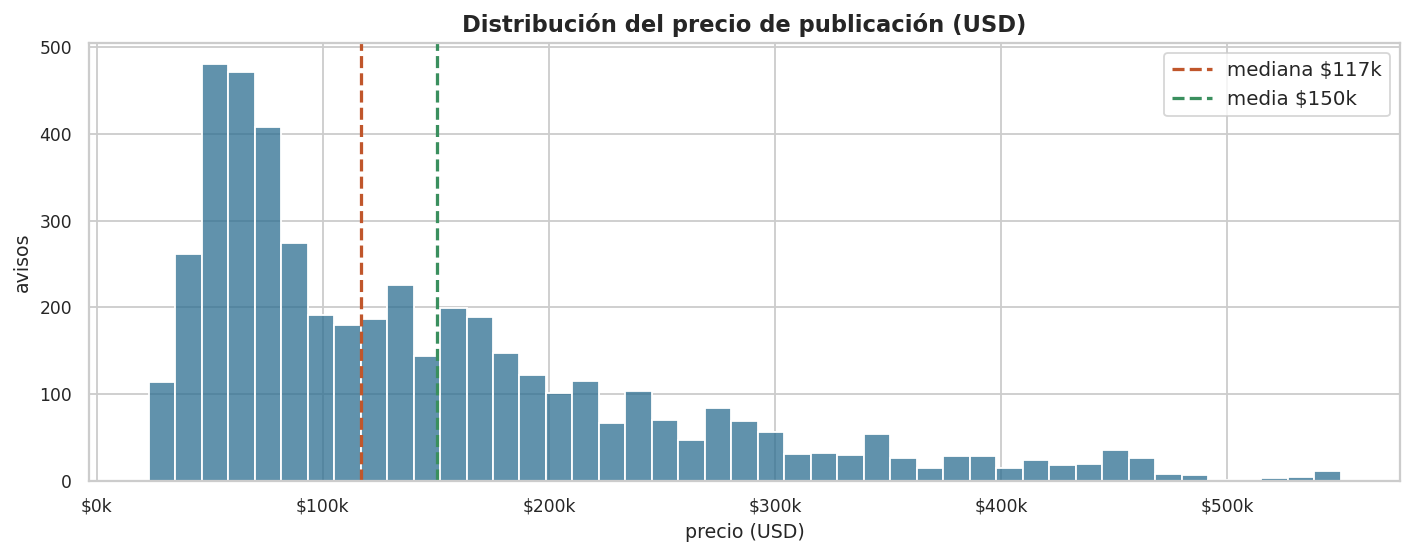

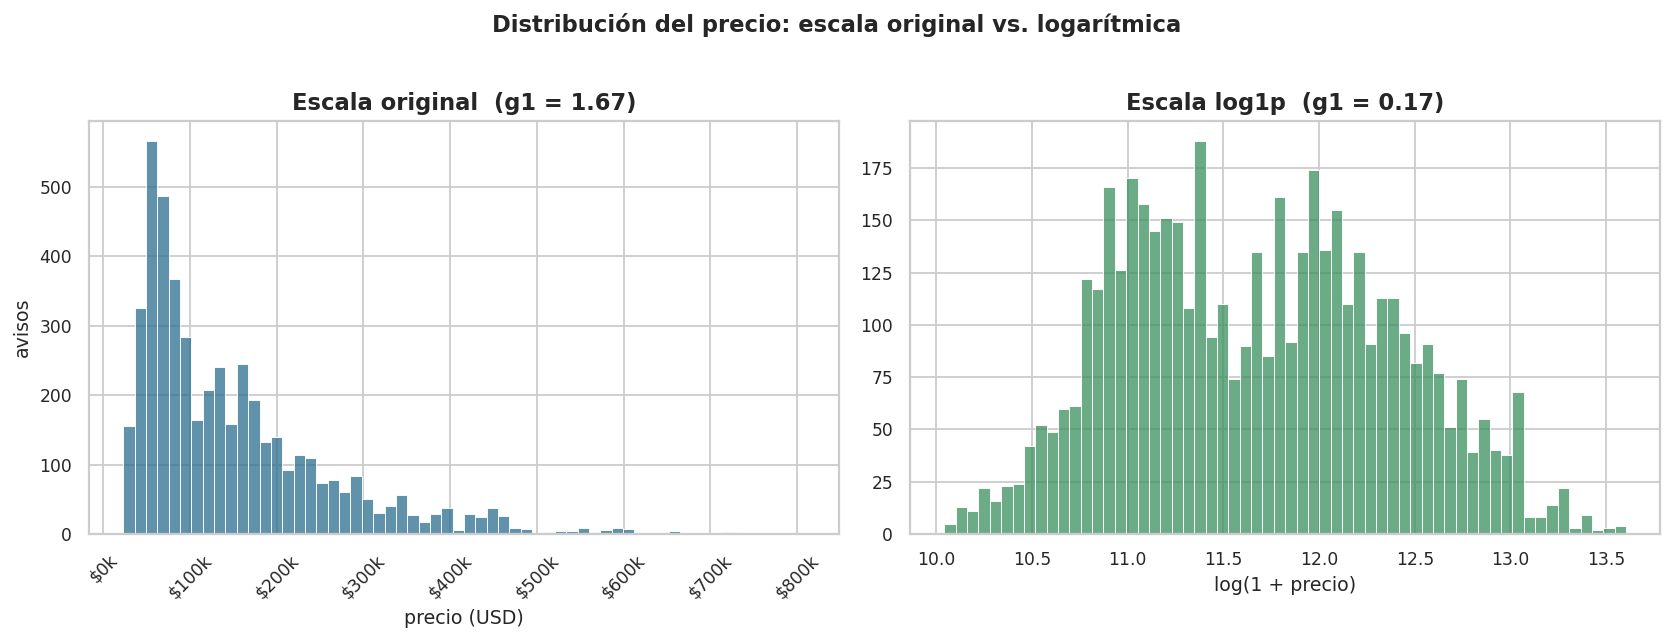

,Precio USD,Precio USD/m2
count,4765.0,4639.0
mean,150329.0,1742.0
std,113649.0,581.0
min,23000.0,167.0
5%,40000.0,904.0
25%,65000.0,1306.0
50%,117000.0,1683.0
75%,196080.0,2115.0
95%,390000.0,2733.0
99%,550000.0,3382.0


In [5]:
precio, pm2 = num("eda_precio_usd"), num("eda_precio_m2")
med, mean = precio.median(), precio.mean()
q1, q3 = precio.quantile(.25), precio.quantile(.75)
p99 = precio.quantile(.99); g1, g1log = skew(precio), skew(np.log1p(precio))

fig, ax = plt.subplots(figsize=(11, 4.4))
sns.histplot(precio[precio <= p99], bins=45, color=PAL, edgecolor="white", ax=ax)
ax.xaxis.set_major_formatter(FuncFormatter(money))
ax.axvline(med, color=PAL2, ls="--", lw=1.8, label=f"mediana {money(med)}")
ax.axvline(mean, color=ACCENT, ls="--", lw=1.8, label=f"media {money(mean)}")
ax.set(title="Distribución del precio de publicación (USD)", xlabel="precio (USD)", ylabel="avisos")
ax.legend(); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
sns.histplot(precio.dropna(), bins=60, color=PAL, ax=axs[0])
axs[0].xaxis.set_major_formatter(FuncFormatter(money))
axs[0].tick_params(axis="x", rotation=45)
axs[0].set(title=f"Escala original  (g1 = {g1:.2f})", xlabel="precio (USD)", ylabel="avisos")
sns.histplot(np.log1p(precio.dropna()), bins=60, color=ACCENT, ax=axs[1])
axs[1].set(title=f"Escala log1p  (g1 = {g1log:.2f})", xlabel="log(1 + precio)", ylabel="")
fig.suptitle("Distribución del precio: escala original vs. logarítmica", y=1.02, fontsize=12.5, fontweight="bold")
plt.show()
display(pd.DataFrame({"Precio USD": precio.describe(percentiles=[.05,.25,.5,.75,.95,.99]),
                      "Precio USD/m2": pm2.describe(percentiles=[.05,.25,.5,.75,.95,.99])}).round(0))

El precio de publicación tiene una **mediana de USD 117k y una media de USD 150k**;
que la media supere a la mediana ya anticipa la asimetría. El 50 % central de la oferta se publica
entre USD 65k y USD 196k, y el 5 % más caro supera holgadamente los USD 390k, con una cola que llega
hasta valores millonarios correspondientes a unidades premium. La asimetría cruda es **g₁ ≈ 1.67**,
un valor alto , compatible con la cola pesada a la derecha. Al aplicar $\log(1+x)$ la asimetría cae a
**0.17**, es decir, la distribución se vuelve prácticamente simétrica.

Esto tiene una consecuencia directa sobre el diseño: el **log-precio es una escala candidata natural**
para el modelado, especialmente para el baseline hedónico y para estabilizar la varianza. Ahora
bien, adoptarla obliga a tratar de manera explícita el *retransformation bias* al comunicar
resultados en dólares, porque $\mathbb{E}[e^{\hat{y}}]\neq e^{\mathbb{E}[\hat{y}]}$: no alcanza
con exponenciar la predicción media. La corrección clásica es el *smearing estimator* de
**Duan (1983)**, y **Gyger et al. (2026)** aplican una corrección análoga al volver de log-renta a
escala monetaria. Dejamos la comparación `precio` vs. `log(precio)` como una decisión a validar
empíricamente —siguiendo el criterio de **Kuhn & Johnson (2013)** de no fijar transformaciones del
target a priori—, no como un supuesto cerrado.

### Normalidad del target: Q-Q plot y curtosis

Complementamos la asimetría con dos diagnósticos de normalidad. La **curtosis** (cuarto momento
estandarizado) mide el peso de las colas; reportamos la versión de **exceso** (curtosis − 3), donde
$0$ corresponde a la distribución normal:

$$ g_2 = \frac{\tfrac{1}{n}\sum_i (x_i-\bar x)^4}{\left[\tfrac{1}{n}\sum_i (x_i-\bar x)^2\right]^2} - 3 $$

El **gráfico cuantil-cuantil (Q-Q)** compara los cuantiles empíricos con los de una normal teórica:
si los puntos caen sobre la recta, la distribución es aproximadamente normal; las desviaciones
sistemáticas en los extremos delatan colas pesadas o asimetría.

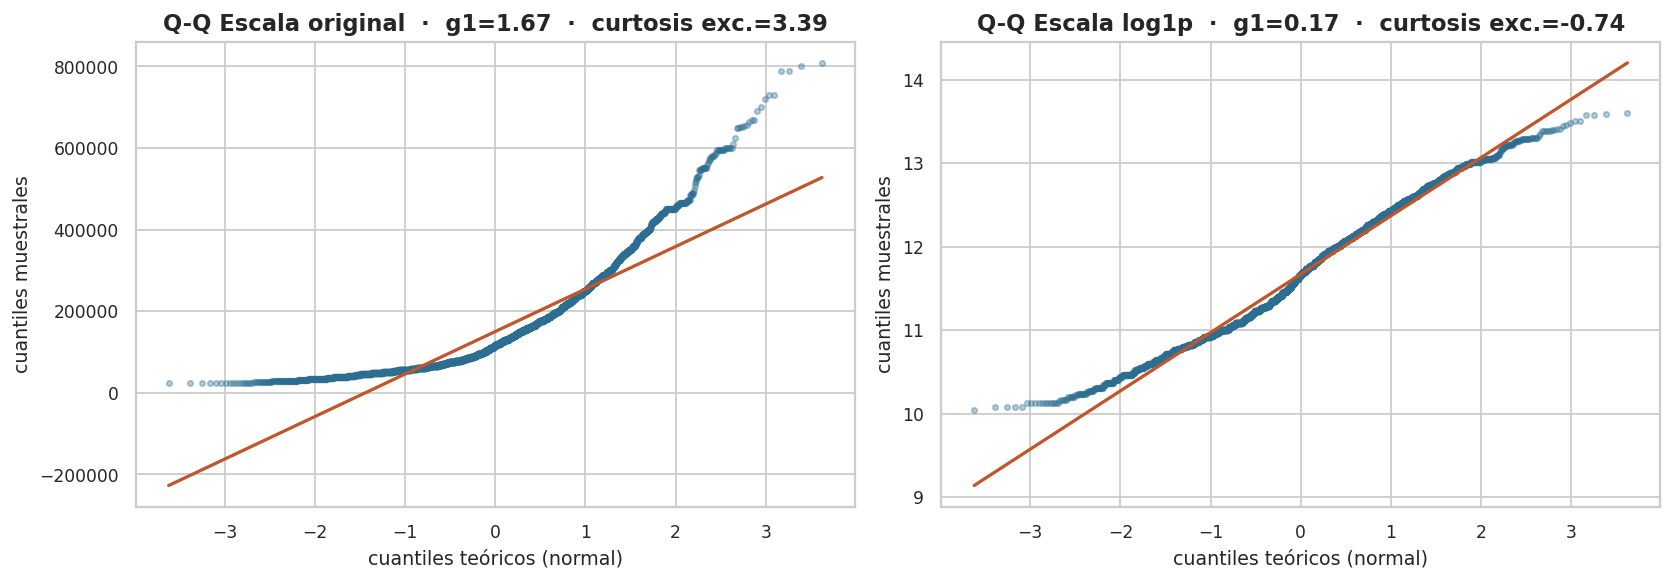

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, serie, t in zip(axs, [precio.dropna(), np.log1p(precio.dropna())],
                        ["Escala original", "Escala log1p"]):
    stats.probplot(serie, dist="norm", plot=ax)
    ax.get_lines()[0].set(marker="o", markersize=3, alpha=.35, color=PAL)
    ax.get_lines()[1].set(color=PAL2, lw=1.8)
    ax.set(title=f"Q-Q {t}  ·  g1={skew(serie):.2f}  ·  curtosis exc.={stats.kurtosis(serie, fisher=True):.2f}",
           xlabel="cuantiles teóricos (normal)", ylabel="cuantiles muestrales")
plt.show()

En **escala original** el Q-Q se curva con fuerza hacia arriba en la cola derecha
y la curtosis de exceso es marcadamente positiva (colas pesadas): el precio está lejos de la normal.
En **log1p**, los puntos se alinean mucho mejor con la recta y la curtosis se acerca a $0$, lo que
—junto con la caída de la asimetría a ~0,17— es consistente con que la transformación logarítmica **normaliza
el target**. Se aprecia además una leve **bimodalidad** en el log-precio (dos tramos de pendiente en
el Q-Q y dos jorobas en el histograma), compatible con la coexistencia de **dos segmentos de mercado**
—por ejemplo usado vs. a estrenar, o gama media vs. premium— que el modelado podrá recoger mediante
covariables o interacciones. Formalmente, contrastar la normalidad con un test como Shapiro-Wilk o
Anderson-Darling excede al EDA; aquí basta el diagnóstico gráfico para orientar la escala del modelo.

### Precio por metro cuadrado

El **valor unitario** (USD/m²) normaliza por tamaño y suele ser más estable que el precio total,
por lo que es un buen resumen del "nivel de precio" de cada zona.

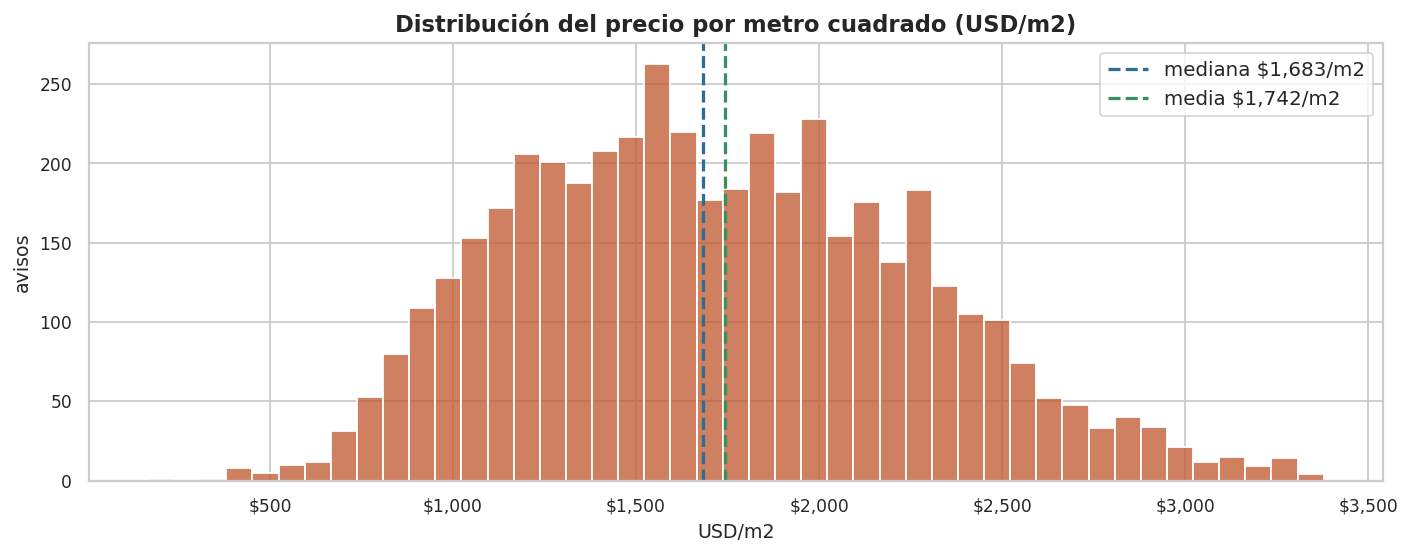

In [7]:
pm2v = pm2.dropna(); pm99 = pm2v.quantile(.99)
fig, ax = plt.subplots(figsize=(11, 4.4))
sns.histplot(pm2v[pm2v <= pm99], bins=45, color=PAL2, edgecolor="white", ax=ax)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _=None: usd(x)))
ax.axvline(pm2v.median(), color=PAL, ls="--", lw=1.8, label=f"mediana {usd(pm2v.median())}/m2")
ax.axvline(pm2v.mean(), color=ACCENT, ls="--", lw=1.8, label=f"media {usd(pm2v.mean())}/m2")
ax.set(title="Distribución del precio por metro cuadrado (USD/m2)", xlabel="USD/m2", ylabel="avisos")
ax.legend(); plt.show()

El precio por m² se distribuye de forma **mucho más simétrica** que el precio
total (mediana ≈ media, en torno a los **1.760–1.790 USD/m²**), con la mayor parte de la oferta
concentrada entre 1.500 y 2.000 USD/m². Esta forma acampanada sugiere un mercado con un valor
unitario relativamente homogéneo dentro del distrito, sobre el que las diferencias de barrio,
tamaño y calidad introducen la dispersión que analizaremos en las secciones siguientes.

## 5. Variables numéricas continuas

Analizamos la superficie total y cubierta —los predictores estructurales más fuertes— y las
expensas. Para cada una reportamos su asimetría $g_1$, que anticipa si conviene transformarlas.

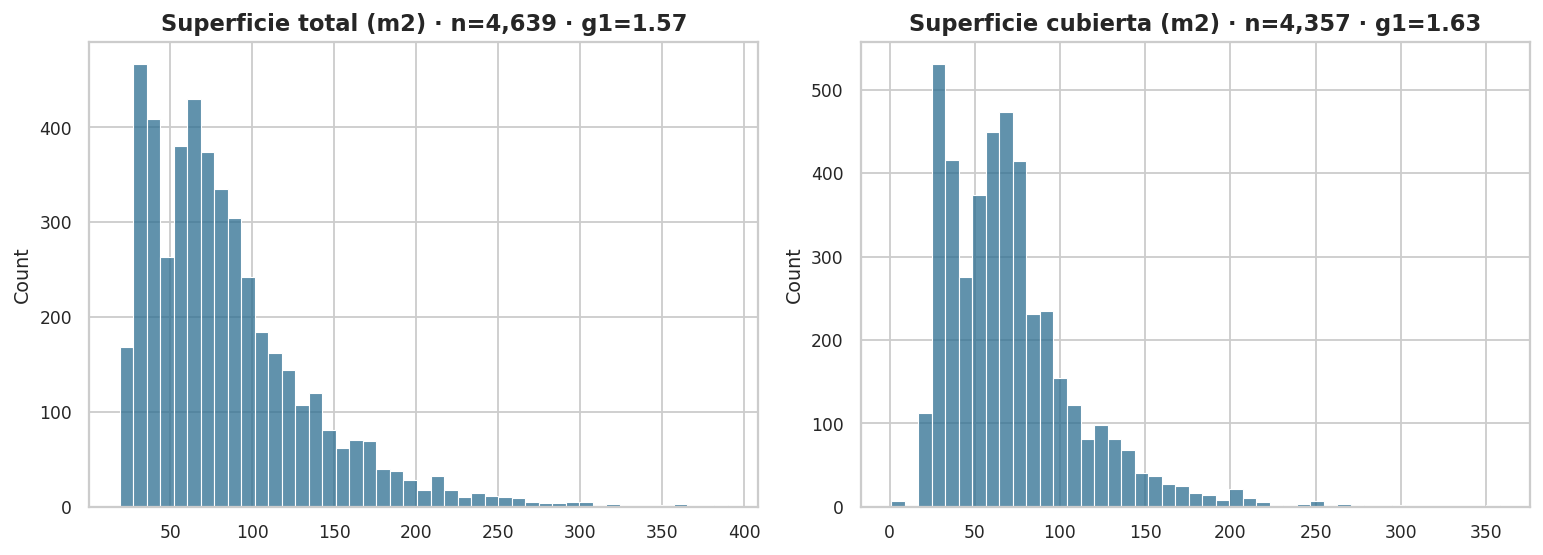

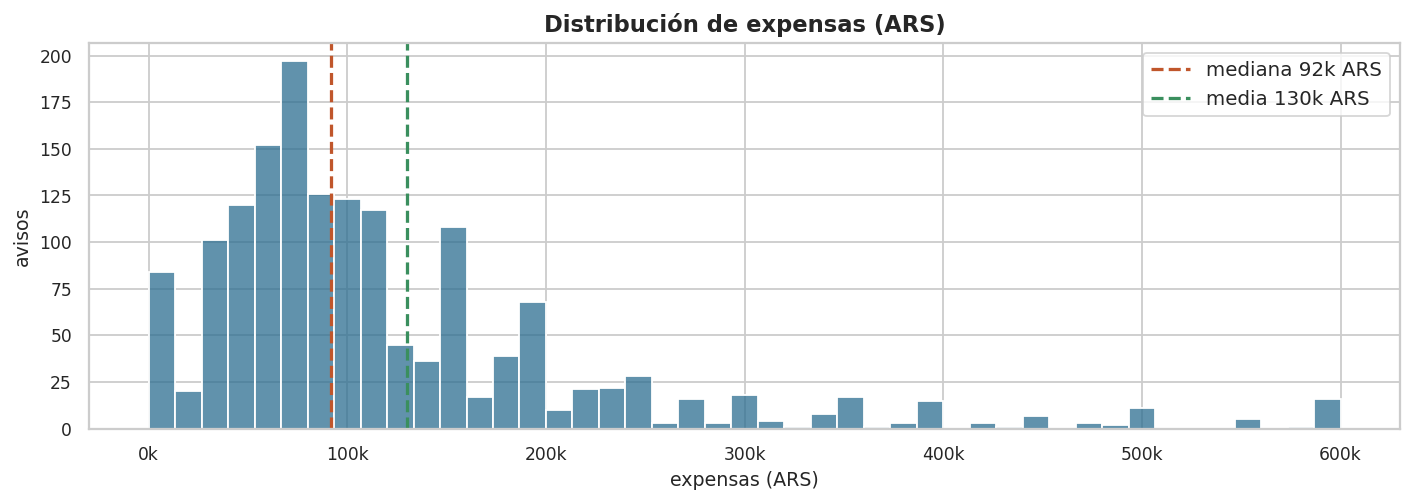

Sólo el 33% de los avisos informa expensas.


In [8]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, (c, t) in zip(axs, [("eda_superficie_total_m2", "Superficie total (m2)"),
                            ("eda_superficie_cubierta_m2", "Superficie cubierta (m2)")]):
    s = num(c).dropna(); sns.histplot(s, bins=45, color=PAL, ax=ax)
    ax.set(title=f"{t} · n={len(s):,} · g1={skew(s):.2f}", xlabel="")
plt.show()

# expensas: escala legible en ARS
ex = num("eda_expensas").dropna(); ex99 = ex.quantile(.99); ex_na = num("eda_expensas").isna().mean()*100
fig, ax = plt.subplots(figsize=(11, 4))
sns.histplot(ex[ex <= ex99], bins=45, color=PAL, edgecolor="white", ax=ax)
ax.xaxis.set_major_formatter(FuncFormatter(kfmt))
ax.axvline(ex.median(), color=PAL2, ls="--", lw=1.8, label=f"mediana {kfmt(ex.median())} ARS")
ax.axvline(ex.mean(), color=ACCENT, ls="--", lw=1.8, label=f"media {kfmt(ex.mean())} ARS")
ax.set(title="Distribución de expensas (ARS)", xlabel="expensas (ARS)", ylabel="avisos"); ax.legend(); plt.show()
print(f"Sólo el {100-ex_na:.0f}% de los avisos informa expensas.")

La **superficie total** es asimétrica a derecha: la mayoría de las unidades se
concentra por debajo de los 100 m² y unas pocas propiedades grandes estiran la cola. Este perfil
sugiere que, en el baseline hedónico, la superficie podría entrar transformada (logaritmo o splines)
para capturar rendimientos marginales decrecientes —el tipo de ingeniería de predictores numéricos
que sistematizan **Kuhn & Johnson (2019)**—; los modelos de árboles (Random Forest, LightGBM), en
cambio, no lo requieren porque particionan el espacio de forma no lineal. La **superficie
cubierta** sigue un patrón análogo pero con más faltantes. Las **expensas** presentan una asimetría
todavía mayor y, sobre todo, un **alto nivel de no informado**: sólo alrededor de un cuarto de los
avisos las declara. Ese vacío es en gran medida **estructural** (muchos anunciantes simplemente no
las cargan), lo que condiciona su uso como predictor y obliga a un tratamiento cuidadoso en la
imputación.

## 6. Variables discretas y categóricas

Las variables de **conteo** (ambientes, dormitorios, baños, cocheras) son discretas y las tratamos
como tales, con etiquetas enteras y ordenadas por valor. Las **nominales** (disposición,
orientación, antigüedad) se describen por frecuencia. Recordamos que en un aviso inmobiliario el
faltante puede significar **ausencia** (p. ej. "sin cochera") y no un dato desconocido.

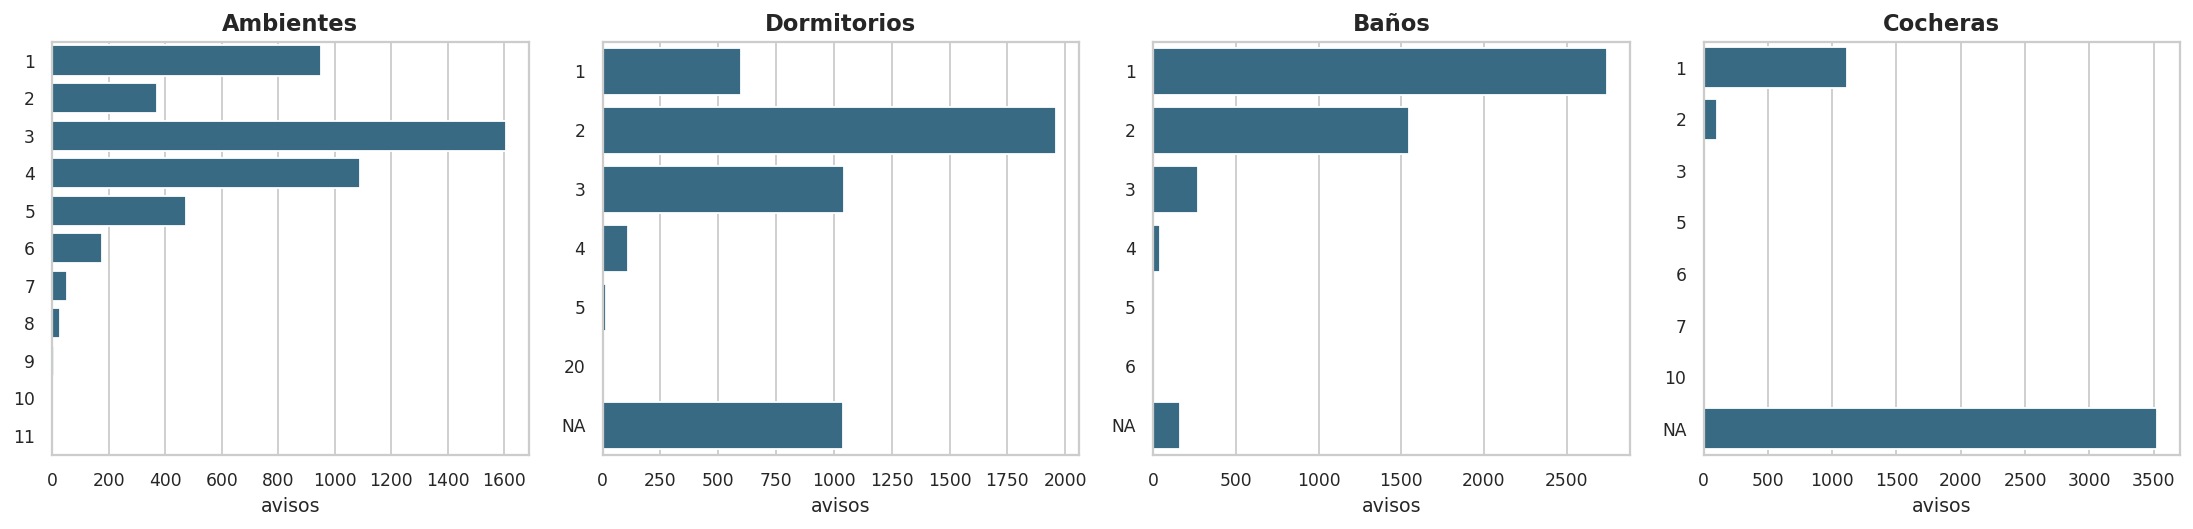

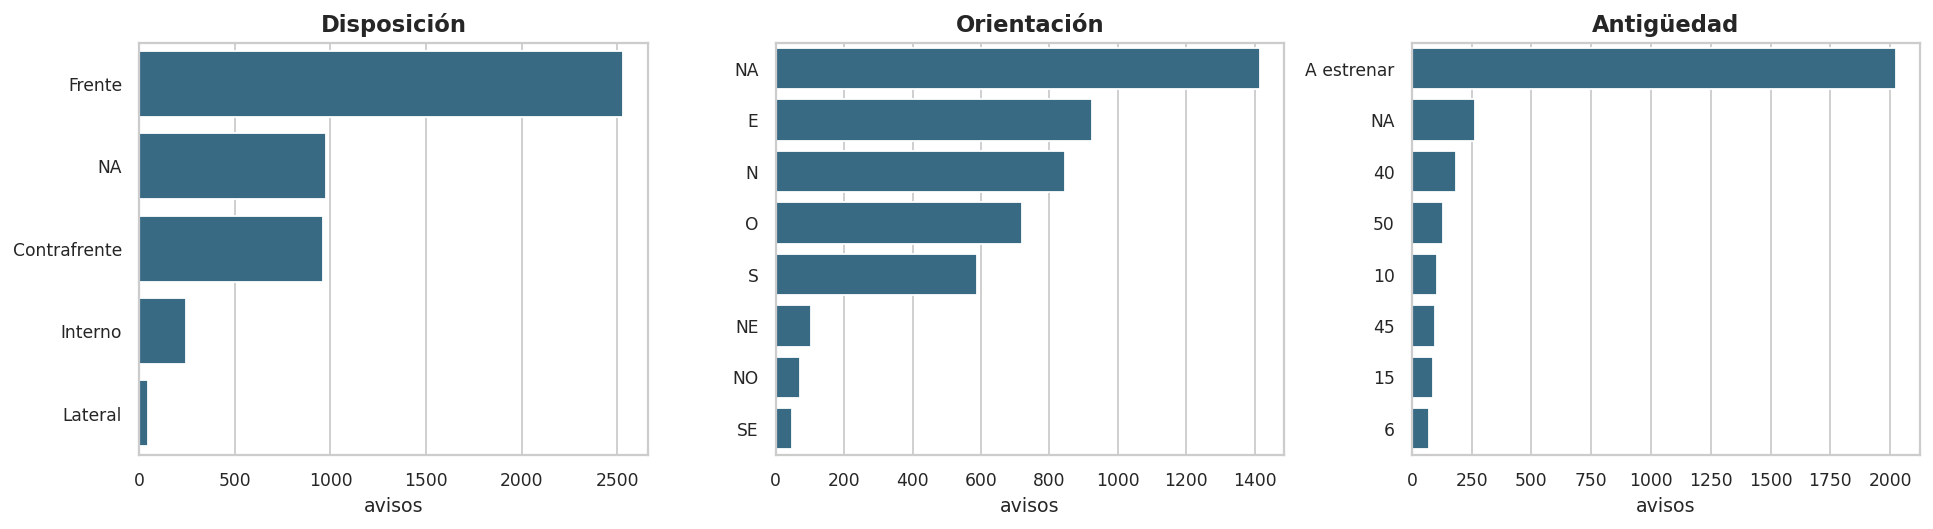

In [9]:
def barra(ax, col, titulo, por_valor=False, top=8):
    vc = df[col].map(etiqueta).value_counts()
    if por_valor:
        vc = vc.reindex(sorted(vc.index, key=lambda x: (0, int(x)) if x.lstrip("-").isdigit() else (1, 10**9)))
    else:
        vc = vc.head(top)
    sns.barplot(x=vc.values, y=list(vc.index), color=PAL, ax=ax)
    ax.set(title=titulo, xlabel="avisos", ylabel="")

fig, axs = plt.subplots(1, 4, figsize=(17, 4.2))
for ax, (c, t) in zip(axs, [("ambientes","Ambientes"),("dormitorios","Dormitorios"),
                            ("eda_banos","Baños"),("eda_cocheras","Cocheras")]):
    barra(ax, c, t, por_valor=True)
plt.show()

fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (c, t) in zip(axs, [("disposicion","Disposición"),("orientacion","Orientación"),("antiguedad","Antigüedad")]):
    barra(ax, c, t)
plt.show()

La oferta está dominada por unidades de **3 ambientes**, seguidas por las de 4 y
las de 1 —un perfil típico de un centro urbano consolidado, con presencia tanto de departamentos
familiares como de monoambientes de inversión—. En **dormitorios** aparece un valor **"20"** que es
claramente un error de carga (ningún departamento del Centro tiene veinte dormitorios): queda
marcado para su tratamiento en el preprocesamiento, no se corrige aquí. Los **baños** concentran su
masa en 1 y 2, y las **cocheras** son mayoritariamente "NA": en este caso el vacío no es un dato
perdido sino la indicación de que la unidad **no tiene cochera**, por lo que corresponde un
tratamiento semántico y no una imputación numérica. Disposición y orientación exhiben un alto nivel
de no informado, coherente con campos que el anunciante suele omitir.

Vale una nota técnica sobre el formato: las columnas con faltantes se almacenan como `float` en
pandas (el `NaN` fuerza ese tipo), y por eso el dato crudo muestra `1.0`, `2.0`, etc.; aquí las
re-etiquetamos como enteros para facilitar la lectura, sin alterar el dato subyacente.

## 7. Valor por barrio oficial

Combinamos el precio por m² con el barrio oficial asignado por cruce geográfico. El **boxplot**
resume, para cada barrio, la mediana, el rango intercuartílico $\text{IQR}=Q_3-Q_1$ y los bigotes
en $[\,Q_1-1{,}5\,\text{IQR},\ Q_3+1{,}5\,\text{IQR}\,]$; los puntos fuera son atípicos.

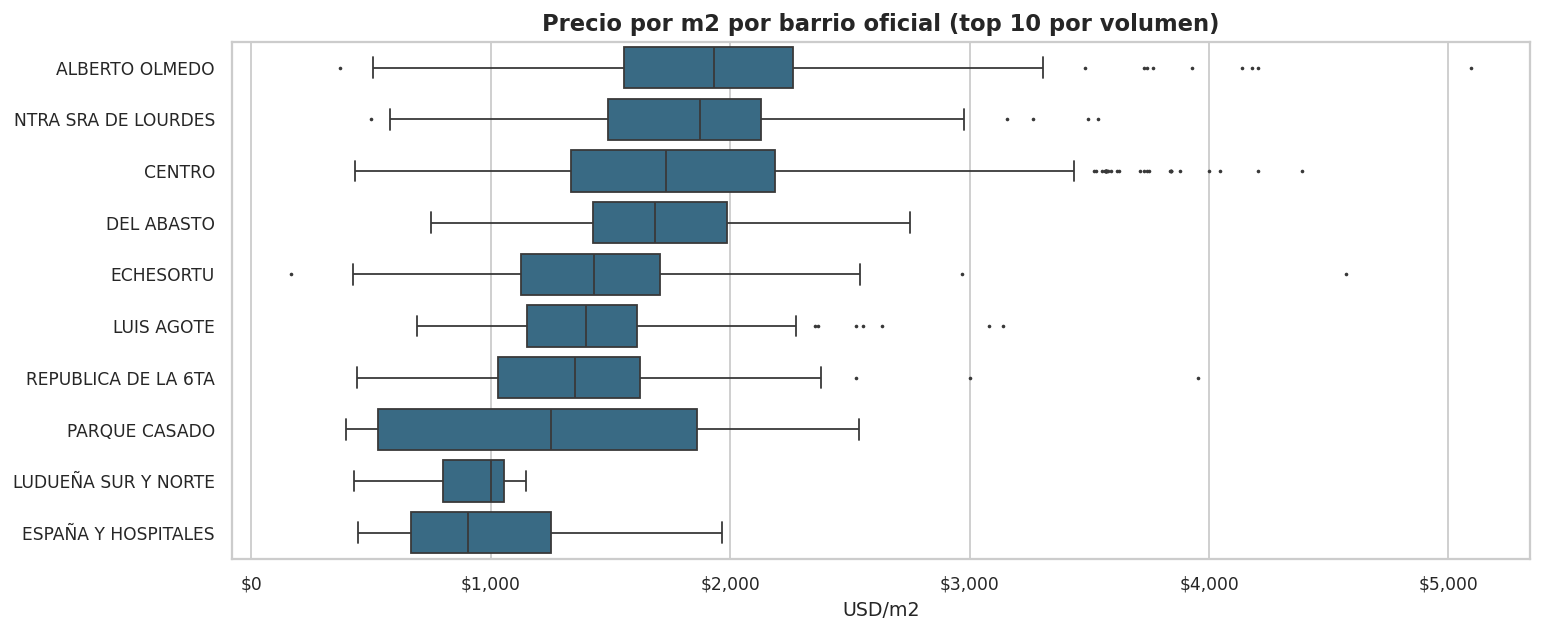

,avisos,mediana USD/m2,media USD/m2
barrio_oficial_geo,,,
ALBERTO OLMEDO,458,1932.0,1928.0
NTRA SRA DE LOURDES,421,1875.0,1828.0
CENTRO,2782,1732.0,1791.0
DEL ABASTO,273,1685.0,1708.0
ECHESORTU,251,1433.0,1454.0
LUIS AGOTE,130,1400.0,1417.0
REPUBLICA DE LA 6TA,267,1351.0,1382.0
PARQUE CASADO,11,1250.0,1277.0
LUDUEÑA SUR Y NORTE,9,1000.0,900.0


In [10]:
top = df["barrio_oficial_geo"].value_counts().head(10).index
sub = df[df["barrio_oficial_geo"].isin(top)].copy(); sub["pm2"] = num("eda_precio_m2")
orden = sub.groupby("barrio_oficial_geo")["pm2"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=sub, x="pm2", y="barrio_oficial_geo", order=orden, color=PAL, fliersize=1, ax=ax)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _=None: usd(x)))
ax.set(title="Precio por m2 por barrio oficial (top 10 por volumen)", xlabel="USD/m2", ylabel=""); plt.show()
tb = sub.groupby("barrio_oficial_geo")["pm2"].agg(["count","median","mean"]).reindex(orden).round(0)
tb.columns = ["avisos","mediana USD/m2","media USD/m2"]; display(tb)

Existe una **heterogeneidad territorial marcada** del valor unitario. Los barrios
encabezan y cierran el ranking con diferencias de mediana relevantes, lo que es consistente con que la
**localización aporta información de precio** por encima de los atributos estructurales. Este
resultado es la primera evidencia a favor de incorporar variables de microlocalización y de estudiar
formalmente la dependencia espacial (sección 9). Como se anticipó, los barrios con pocos avisos
—cuya mediana descansa sobre una muestra chica— se interpretan con prudencia: su posición en el
ranking puede reflejar variabilidad muestral más que un nivel de precio estable.

## 8. Relaciones entre variables

Medimos la asociación entre las numéricas con dos coeficientes complementarios. El de **Pearson**
(Pearson, 1895) capta asociación **lineal**; el de **Spearman** (Spearman, 1904) es el mismo
coeficiente aplicado sobre los **rangos** y capta asociación **monótona** (robusto a no linealidades
y a outliers):

$$ r=\frac{\sum_i (x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum_i (x_i-\bar x)^2}\sqrt{\sum_i (y_i-\bar y)^2}}
\qquad \rho = r_{\text{sobre rangos}} $$

La recta superpuesta al diagrama de dispersión es la regresión por **mínimos cuadrados ordinarios**
(atribuida a Legendre, 1805, y Gauss, 1809), que estima $a,b$ minimizando $\sum_i (y_i-(a+b\,x_i))^2$;
**Montgomery, Peck & Vining (2012)** es la referencia que seguiremos para el baseline hedónico.
Comparar $r$ y $\rho$ es útil porque una diferencia grande entre ambos delata no linealidad o
influencia de valores extremos.

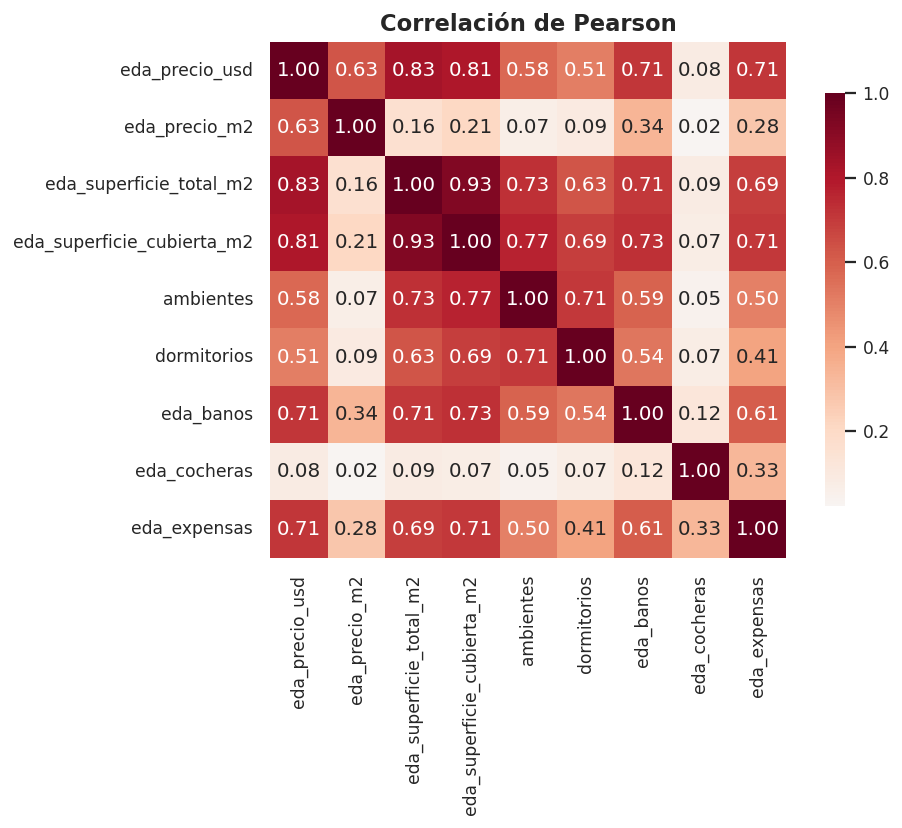

,rho Spearman con log(precio)
eda_superficie_total_m2,0.881
eda_superficie_cubierta_m2,0.859
eda_banos,0.742
eda_expensas,0.661
ambientes,0.648
eda_precio_m2,0.613
dormitorios,0.554
eda_cocheras,0.248


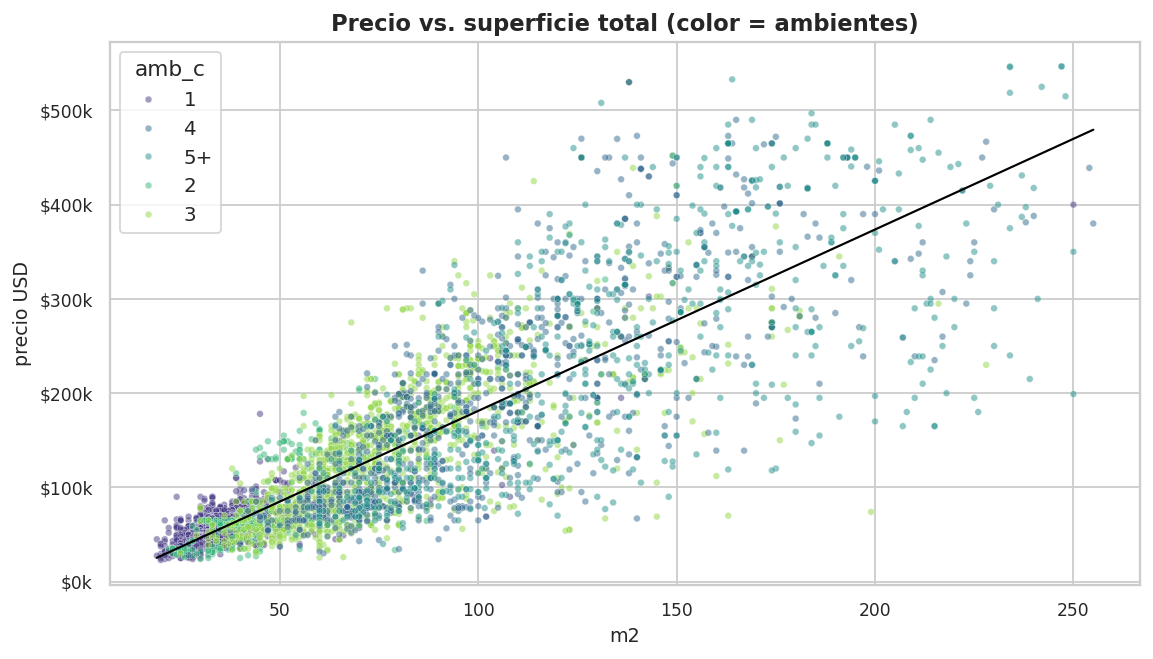

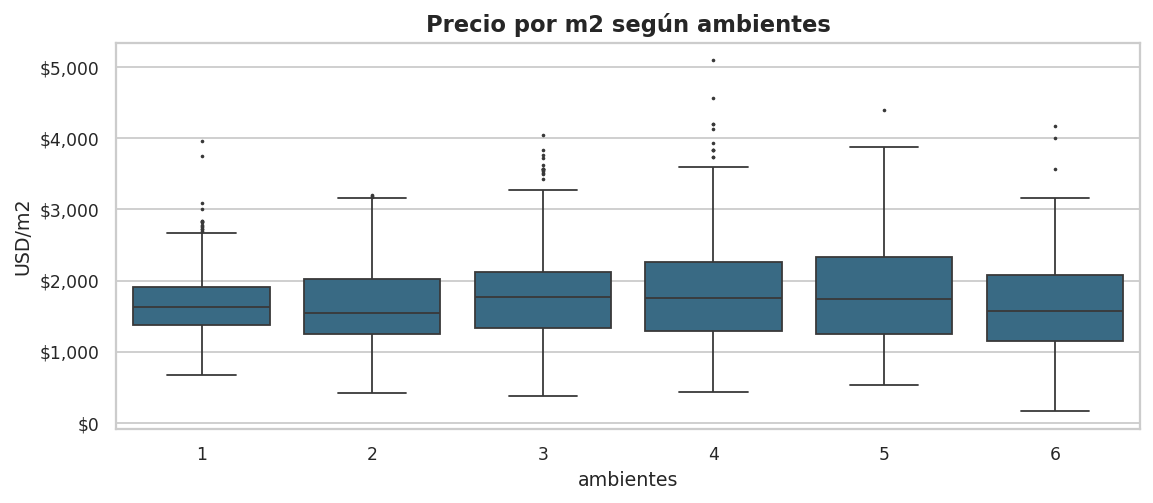

In [11]:
cols = ["eda_precio_usd","eda_precio_m2","eda_superficie_total_m2","eda_superficie_cubierta_m2",
        "ambientes","dormitorios","eda_banos","eda_cocheras","eda_expensas"]
Mn = df[cols].apply(pd.to_numeric, errors="coerce")
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(Mn.corr("pearson"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True, cbar_kws={"shrink":.8}, ax=ax)
ax.set_title("Correlación de Pearson"); plt.show()

logp = np.log1p(precio)
rank = Mn.drop(columns=["eda_precio_usd"]).apply(lambda c: spearman(c, logp)).sort_values(key=abs, ascending=False)
display(rank.to_frame("rho Spearman con log(precio)").round(3))

sc = pd.DataFrame({"sup": num("eda_superficie_total_m2"), "precio": precio, "amb": df["ambientes"]}).dropna()
sc = sc[(sc["sup"] < sc["sup"].quantile(.99)) & (sc["precio"] < sc["precio"].quantile(.99))]
sc["amb_c"] = sc["amb"].clip(upper=5).astype(int).astype(str).replace("5","5+")
fig, ax = plt.subplots(figsize=(9, 5.2))
sns.scatterplot(data=sc, x="sup", y="precio", hue="amb_c", palette="viridis", s=14, alpha=.5, ax=ax)
# recta de mínimos cuadrados (numpy polyfit, sin depender de scipy)
_b, _a = np.polyfit(sc["sup"], sc["precio"], 1)
_xs = np.linspace(sc["sup"].min(), sc["sup"].max(), 100)
ax.plot(_xs, _a + _b * _xs, color="black", lw=1.2, label="ajuste OLS")
ax.yaxis.set_major_formatter(FuncFormatter(money))
ax.set(title="Precio vs. superficie total (color = ambientes)", xlabel="m2", ylabel="precio USD"); plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
sc2 = pd.DataFrame({"pm2": pm2, "amb": df["ambientes"].clip(upper=6)}).dropna()
sns.boxplot(data=sc2, x="amb", y="pm2", color=PAL, fliersize=1, ax=ax)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _=None: usd(x)))
ax.set(title="Precio por m2 según ambientes", xlabel="ambientes", ylabel="USD/m2"); plt.show()

La **superficie total** es, como predice la teoría de precios hedónicos
(**Rosen, 1974**), la variable más correlacionada con el precio (asociación fuerte y positiva, tanto
en Pearson como en Spearman sobre el log-precio). El diagrama de dispersión es consistente con una relación
positiva y aproximadamente lineal en dólares, pero con la nube **abriéndose** a medida que crece la
superficie: esta heterocedasticidad —mayor varianza del precio en las unidades grandes— es otra señal
a favor de modelar en escala logarítmica, y es justamente el tipo de patrón que el análisis de
residuos de **Montgomery, Peck & Vining (2012)** busca detectar. El número de ambientes ordena
visualmente la nube, lo que anticipa **interacciones** entre tamaño y tipología; siguiendo a
**Kuhn & Johnson (2019)**, las tratamos como hipótesis a plantear y validar, no a generar
indiscriminadamente. Por último, el precio por m² **disminuye** al aumentar los ambientes: las
unidades chicas valen relativamente más por metro cuadrado, un patrón conocido (peso de espacios
fijos como baño y cocina) que el modelo deberá reproducir. Que Pearson y Spearman arrojen valores
parecidos indica que las asociaciones son mayormente monótonas, sin quiebres severos.

### Precio según antigüedad, disposición y orientación

Tres atributos cualitativos con peso hedónico reconocido: la **antigüedad** del inmueble, la
**disposición** (frente / contrafrente / interno) y la **orientación**. Comparamos la mediana de
precio/m² entre sus categorías; el orden de cada panel va de mayor a menor mediana.

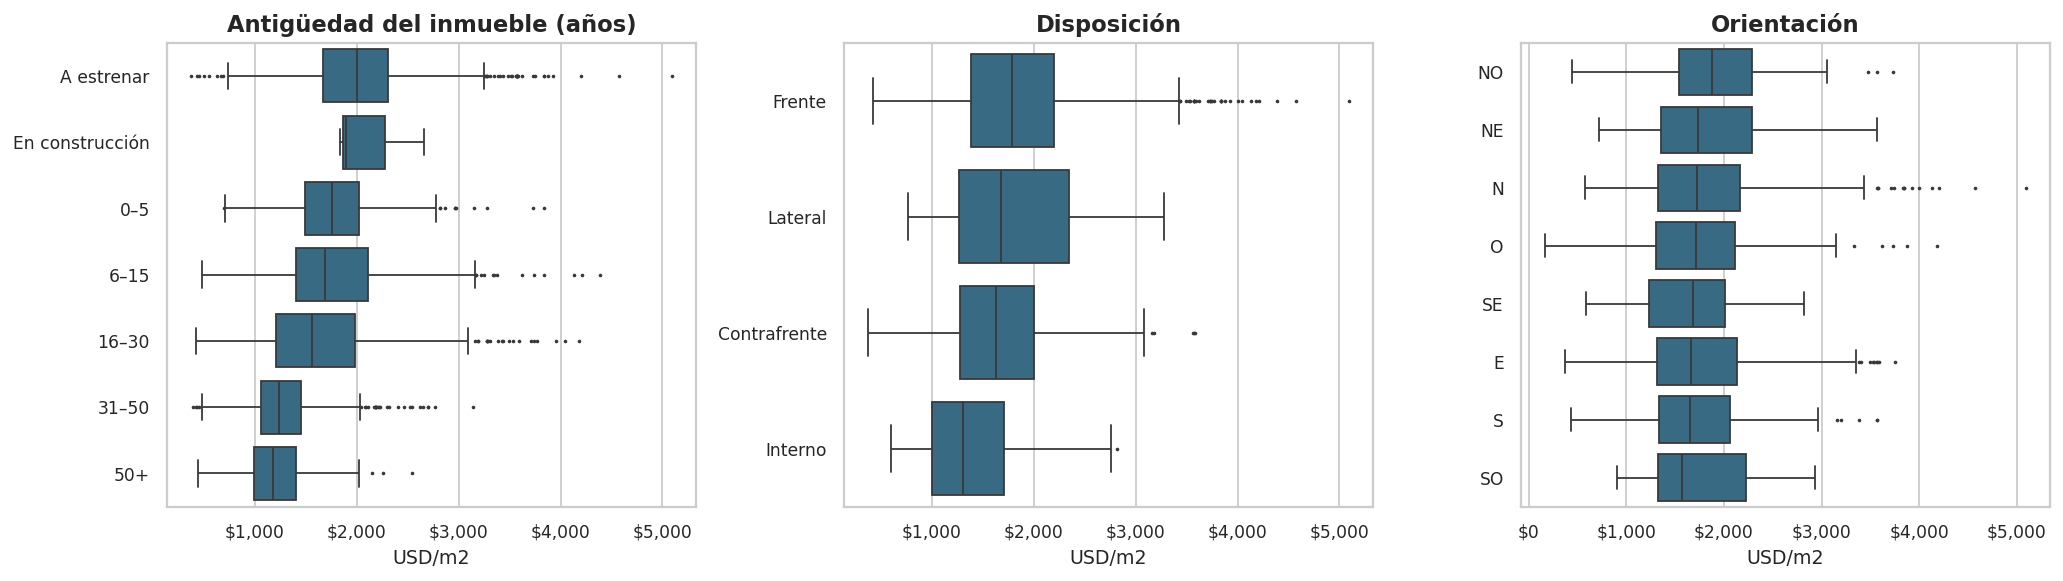

In [12]:
pm2v = num("eda_precio_m2")

# 'antiguedad' mezcla categorías ("A estrenar"/"En construcción") con años numéricos (y algún
# valor erróneo); la agrupamos en tramos con orden cronológico para que sea legible.
def bucket_antig(v):
    s = str(v).strip().lower()
    if "estrenar" in s: return "A estrenar"
    if "construc" in s: return "En construcción"
    try: y = float(str(v).replace(",", "."))
    except ValueError: return None
    if not (0 <= y <= 150): return None          # descarta valores imposibles (p. ej. 792)
    for lo, hi, lab in [(0,5,"0–5"),(6,15,"6–15"),(16,30,"16–30"),(31,50,"31–50"),(51,150,"50+")]:
        if lo <= y <= hi: return lab
ORD_ANTIG = ["A estrenar","En construcción","0–5","6–15","16–30","31–50","50+"]

fig, axs = plt.subplots(1, 3, figsize=(16, 4.6))
# antigüedad (agrupada, orden cronológico)
da = pd.DataFrame({"pm2": pm2v, "cat": df["antiguedad"].map(bucket_antig)}).dropna()
orden = [c for c in ORD_ANTIG if c in set(da["cat"])]
sns.boxplot(data=da, y="cat", x="pm2", order=orden, color=PAL, fliersize=1, ax=axs[0])
axs[0].set(title="Antigüedad del inmueble (años)", xlabel="USD/m2", ylabel="")
# disposición y orientación (orden por mediana)
for ax, col, t in zip(axs[1:], ["disposicion", "orientacion"], ["Disposición", "Orientación"]):
    d = pd.DataFrame({"pm2": pm2v, "cat": df[col].astype(str)}).dropna()
    d = d[~d["cat"].str.lower().isin(["nan", "none", ""])]
    orden = d.groupby("cat")["pm2"].median().sort_values(ascending=False).index
    sns.boxplot(data=d, y="cat", x="pm2", order=orden, color=PAL, fliersize=1, ax=ax)
    ax.set(title=t, xlabel="USD/m2", ylabel="")
for ax in axs: ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _=None: usd(x)))
plt.show()

La **disposición** exhibe la jerarquía hedónica clásica y muy nítida:
**Frente > Lateral > Contrafrente > Interno**, con las unidades internas claramente por debajo — la
exposición y la luz se pagan. La **antigüedad** (agrupada en tramos) tiende a valer más en las
unidades nuevas o recientes y a descender con los años, el sentido esperado; conviene notar que el
campo crudo es **ruidoso** —mezcla años numéricos con categorías y arrastra algún valor imposible
(p. ej. 792)—, algo a **sanear en preprocesamiento**. La **orientación** incide poco y de forma más
ruidosa, con un leve premio para las orientaciones **norte** (N/NE/NO). Son diferencias
**descriptivas** —no controlan por barrio ni superficie, así que parte del efecto puede ser
composición—, pero señalan variables con potencial predictivo y refuerzan conservar estas
categóricas con un encoding adecuado.

## 9. Atributos extraídos del texto

De la descripción libre de cada aviso se derivaron indicadores binarios (`feat_*`) mediante
expresiones regulares con manejo de negaciones (de modo que "sin cochera" **no** active el atributo).
La **prevalencia** de cada atributo es su proporción de aparición, $\text{prev}(f)=\tfrac{1}{n}\sum_i
\mathbb{1}[f_i=1]$.

> **Nota sobre `feat_litoral_gas`.** El nombre puede inducir a confusión, porque *Litoral Gas* es la
> empresa distribuidora de gas de la provincia. La variable **no** identifica a la empresa: captura
> la mención de **conexión a gas natural** en el aviso (el patrón detecta "gas natural" o "litoral
> gas" como sinónimo de servicio de red). Para evitar el equívoco, aquí la mostramos como
> **`gas_natural`**, y conviene renombrar la columna en la etapa de feature engineering.

### Términos frecuentes en las descripciones

Antes de mirar los indicadores derivados, conviene ver el **texto crudo** del que salen. Sobre
`descripcion_completa` calculamos las palabras y los n-gramas (bigramas y trigramas) más frecuentes,
tras normalizar (minúsculas, sin acentos ni signos) y quitar palabras vacías. Esto muestra el
vocabulario real de los avisos y fundamenta las expresiones regulares que generan los `feat_*`.

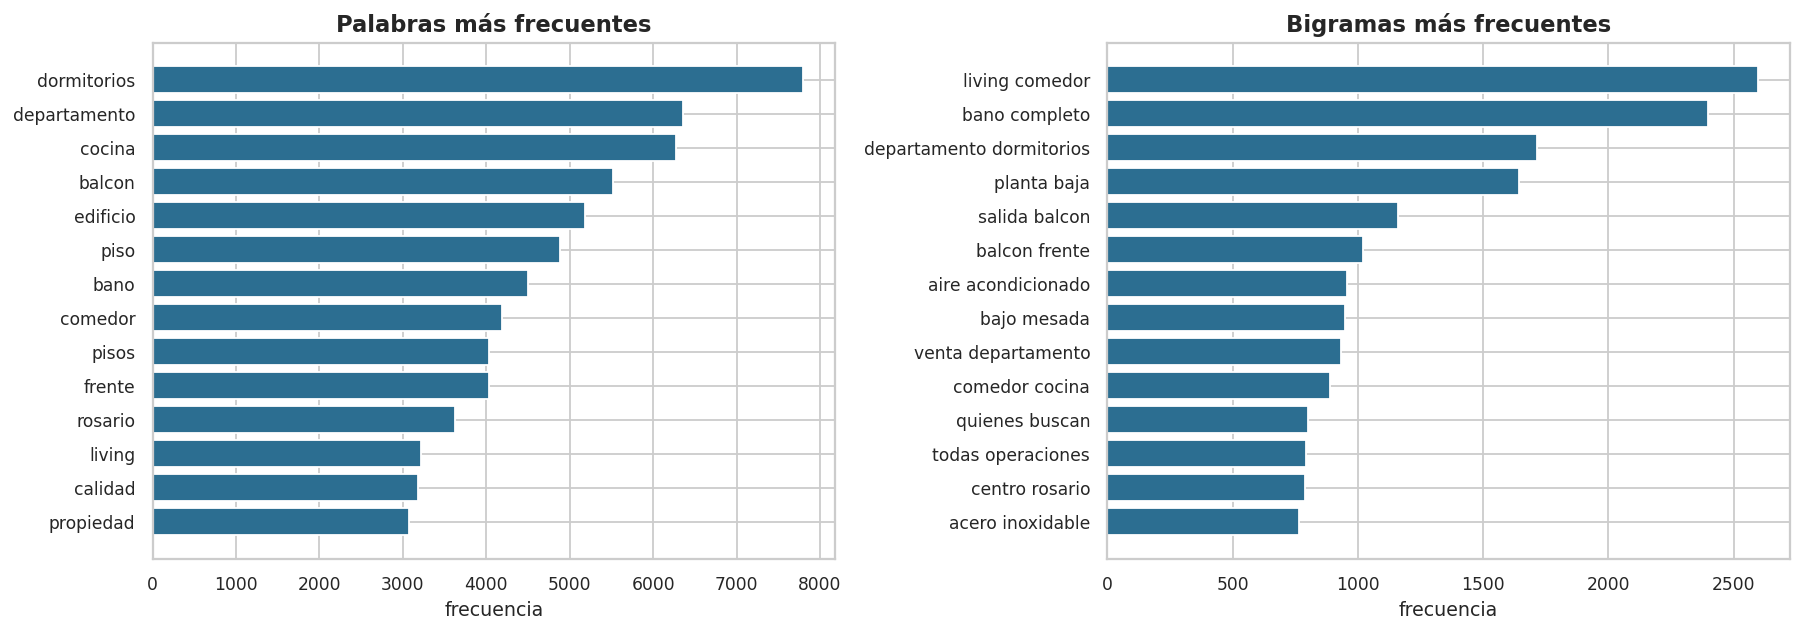

Descripciones analizadas: 4,765


In [13]:
import re, unicodedata
from collections import Counter

STOP = set(("de la el en y a los las un una con por para que del al se su sus es mas muy sin o u lo "
    "le les este esta estos estas como sobre entre me te nos ya son fue ser tiene hay dos tres "
    "cuenta cuentan ademas tambien todo toda desde hasta cada mts mt m2 metros").split())
# HTML + boilerplate del portal (residual en descripcion_completa) y leyenda legal del corredor
JUNK = set(("span class button btn link href verdatos datos ver style div strong nbsp amp "
    "descripciondatosanunciante corredor corretaje publico inmobiliario matricula cucicba").split())

def tokenizar(t):
    t = re.sub(r"<[^>]+>", " ", str(t))       # quita etiquetas HTML
    t = re.sub(r"&[a-z#0-9]+;", " ", t)        # quita entidades HTML (&nbsp; etc.)
    t = unicodedata.normalize("NFKD", t.lower())
    t = "".join(c for c in t if not unicodedata.combining(c))
    return [w for w in re.findall(r"[a-zñ]{3,}", t) if w not in STOP and w not in JUNK]

docs = [tokenizar(t) for t in df["descripcion_completa"].dropna().astype(str)]
def ngramas(n): return Counter(" ".join(d[i:i+n]) for d in docs for i in range(len(d)-n+1))
# Solo palabras y bigramas: los trigramas quedan dominados por la leyenda legal del corredor
frecs = {"Palabras": Counter(w for d in docs for w in d), "Bigramas": ngramas(2)}

fig, axs = plt.subplots(1, 2, figsize=(14, 5))
for ax, (t, cnt) in zip(axs, frecs.items()):
    top = cnt.most_common(14)[::-1]
    ax.barh([k for k, _ in top], [v for _, v in top], color=PAL)
    ax.set(title=f"{t} más frecuentes", xlabel="frecuencia")
plt.show()
print(f"Descripciones analizadas: {len(docs):,}")

Una vez depurado, el vocabulario más frecuente describe **atributos estructurales
y de calidad** (dormitorios, cocina, balcón, comedor, frente…) y los bigramas revelan **frases
recurrentes** propias del rubro (*living comedor*, *baño completo*, *aire acondicionado*, *salida
balcón*, *bajo mesada*). Es la materia prima de los indicadores `feat_*`: es consistente con que las
expresiones regulares capturan atributos realmente presentes y sugiere **candidatos adicionales**
(términos frecuentes sin su `feat_`) para evaluar en feature engineering. Cualquier señal derivada
del texto deberá validarse fuera de muestra (Kuhn & Johnson, 2019).

> **Hallazgo de calidad de dato.** El campo `descripcion_completa` arrastra **HTML residual y
> boilerplate del portal** (etiquetas `<span>`/`<button>`, clases CSS, botones "ver datos") y, sobre
> todo, la **leyenda legal del corredor** que se repite en casi todos los avisos ("corredor público
> inmobiliario"; código civil y comercial; ley de lealtad comercial y de defensa del consumidor). De
> hecho, **los trigramas más frecuentes son íntegramente esa leyenda legal**, no contenido del
> inmueble —por eso se muestran solo palabras y bigramas—. Queda registrado: antes de construir
> cualquier feature de texto en FE hay que **sanear el HTML y remover el boilerplate legal**, o
> contaminarán tanto los tokens como las expresiones regulares.

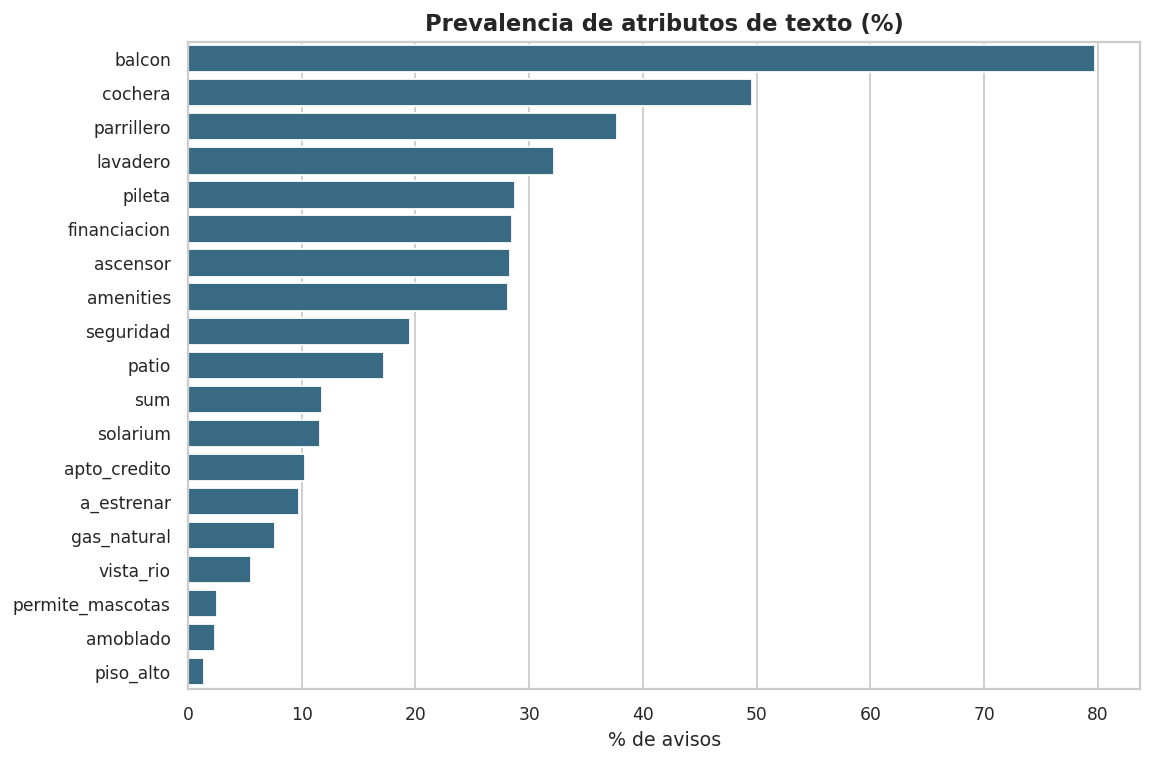

,mediana USD/m2 (con),mediana USD/m2 (sin),delta
atributo,,,
cochera,1983.0,1461.0,522.0
amenities,2107.0,1532.0,575.0
pileta,2118.0,1532.0,585.0
vista_rio,2107.0,1667.0,440.0
a_estrenar,1962.0,1648.0,313.0


In [14]:
feats = [c for c in df.columns if c.startswith("feat_")]
prev = (df[feats].apply(pd.to_numeric, errors="coerce").mean()*100).sort_values(ascending=False)
etiquetas = {c: c.replace("feat_", "").replace("litoral_gas", "gas_natural") for c in prev.index}
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=prev.values, y=[etiquetas[c] for c in prev.index], color=PAL, ax=ax)
ax.set(title="Prevalencia de atributos de texto (%)", xlabel="% de avisos", ylabel=""); plt.show()

clave = ["feat_cochera","feat_amenities","feat_pileta","feat_vista_rio","feat_a_estrenar"]
ef = pd.DataFrame([[etiquetas[f], pm2[num(f)==1].median(), pm2[num(f)==0].median(),
                    pm2[num(f)==1].median()-pm2[num(f)==0].median()] for f in clave if f in df],
                  columns=["atributo","mediana USD/m2 (con)","mediana USD/m2 (sin)","delta"]).set_index("atributo")
display(ef.round(0))

El atributo más frecuente es el **balcón/terraza**, presente en cerca de cuatro de
cada cinco avisos, seguido por la cochera y el parrillero. La comparación de medianas de precio por
m² con y sin cada atributo muestra diferencias en la dirección esperada (amenities, pileta y vista al
río se asocian a valores unitarios más altos), pero **es sólo descriptiva**: no controla por
superficie, barrio ni tipología, de modo que parte de esa diferencia puede deberse a que las
propiedades con esos atributos son, además, más grandes o están mejor ubicadas. Por eso tratamos
estas señales como **hipótesis a validar fuera de muestra** dentro del modelado, y no como efectos:
es la distinción entre *feature discovery* y *feature validation* de **Kuhn & Johnson (2019)**, según
la cual toda señal descubierta mirando el target debe confirmarse en datos donde no fue descubierta.
La aclaración sobre `gas_natural` es, además, un buen ejemplo de por qué conviene documentar la
semántica de cada feature derivada de texto antes de interpretarla.

## 10. Estructura espacial del precio

Más allá del barrio, ¿hay un patrón **continuo** en el espacio? Proyectamos cada propiedad por sus
coordenadas y la coloreamos por precio por m². Si valores similares tienden a agruparse
geográficamente, habrá **autocorrelación espacial**, que en la etapa siguiente se cuantifica con el
**índice de Moran** (**Moran, 1950**):

$$ I=\frac{n}{\sum_i\sum_j w_{ij}}\cdot\frac{\sum_i\sum_j w_{ij}(x_i-\bar x)(x_j-\bar x)}{\sum_i (x_i-\bar x)^2} $$

donde $w_{ij}$ es la matriz de pesos espaciales $W$ (por ejemplo, vecinos más cercanos). La
definición de $W$, el spatial lag y los modelos SAR/SEM siguen a **LeSage & Pace (2009)**, y
**Tapia et al. (2025)** lo aplican a valuación con LightGBM insistiendo en que la autocorrelación
espacial **se mide, no se asume**. Aquí sólo **visualizamos** el patrón; el cálculo formal de $I$ y la
elección de $W$ corresponden a la etapa espacial.

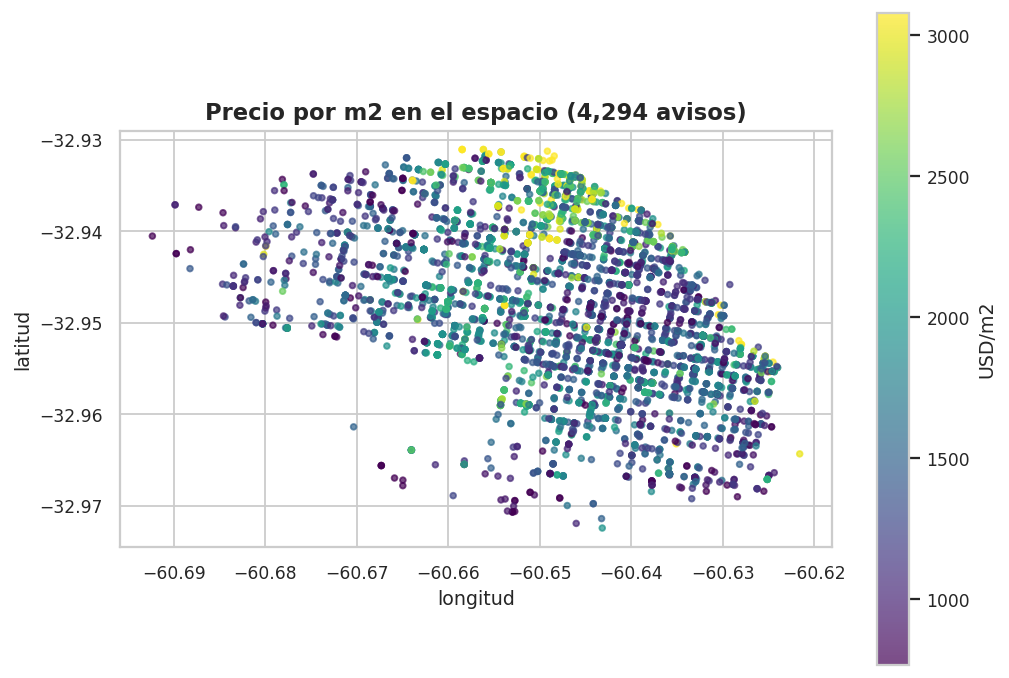

In [15]:
sp = df[df["apto_eda_espacial_v4"] == True].copy()
sp["lat"], sp["lon"], sp["pm2"] = num("eda_latitud"), num("eda_longitud"), num("eda_precio_m2")
sp = sp.dropna(subset=["lat","lon","pm2"])
vmin, vmax = sp["pm2"].quantile(.02), sp["pm2"].quantile(.98)
fig, ax = plt.subplots(figsize=(8, 7.5))
s = ax.scatter(sp["lon"], sp["lat"], c=sp["pm2"].clip(vmin, vmax), cmap="viridis", s=10, alpha=.7)
plt.colorbar(s, ax=ax, shrink=.7, label="USD/m2")
ax.set(title=f"Precio por m2 en el espacio ({len(sp):,} avisos)", xlabel="longitud", ylabel="latitud")
ax.set_aspect("equal", "box"); plt.show()

El mapa revela un **patrón espacial nítido**: el sector **noreste** —hacia el río
Paraná, Pichincha y el eje de Puerto Norte— concentra los mayores precios por m², mientras que el
sur y el oeste del distrito son más económicos. Incluso se distingue la **trama urbana** en la nube
de puntos, señal de la buena calidad de la geolocalización. Este gradiente sugiere **autocorrelación
espacial positiva** y motiva las preguntas centrales del diseño: ¿cuánta de esa estructura espacial
es capturada por las covariables de localización (distancia al río, al centro, densidad de servicios)
y cuánta permanece como dependencia residual? Medir el índice de Moran antes y después de incorporar
información territorial —el *ablation* espacial que plantea Gyger et al.— es la vía para responderlo,
y es exactamente lo que abordan las preguntas de investigación RQ3 y RQ4.

## 11. Calidad de datos y faltantes

Cuantificamos la proporción de faltantes por variable, $\text{missing}(v)=\tfrac{1}{n}\sum_i
\mathbb{1}[x_{iv}=\text{NA}]$, teniendo presente que el **mecanismo** de datos faltantes importa:
la taxonomía MCAR / MAR / MNAR de **Rubin (1976)** distingue si la ausencia es aleatoria o
informativa. En términos prácticos, **Kuhn & Johnson (2019)** advierten que un `NA` no equivale
automáticamente a cero y debe entenderse primero como parte del proceso generador del dato: aquí
varios faltantes son **ausencia estructural** (p. ej. "sin cochera"), no desconocimiento.

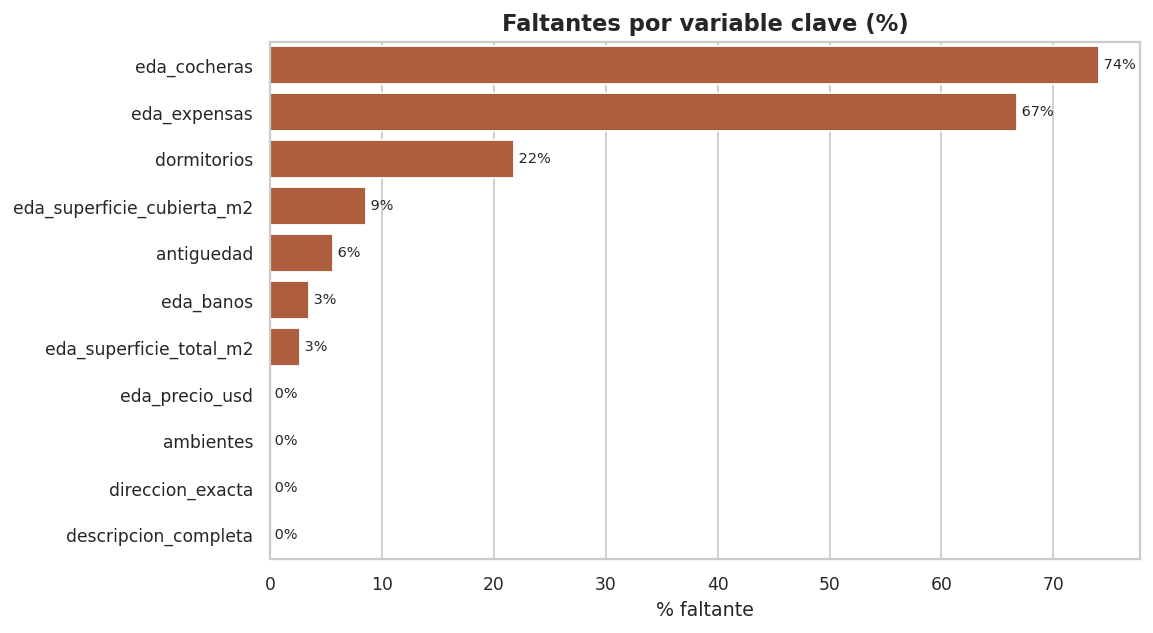

In [16]:
claves = ["eda_precio_usd","ambientes","eda_superficie_total_m2","eda_superficie_cubierta_m2",
          "eda_banos","dormitorios","eda_cocheras","eda_expensas","antiguedad","direccion_exacta","descripcion_completa"]
miss = (df[claves].isna().mean()*100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=miss.values, y=miss.index, color=PAL2, ax=ax)
for i, v in enumerate(miss.values): ax.text(v, i, f" {v:.0f}%", va="center", fontsize=8)
ax.set(title="Faltantes por variable clave (%)", xlabel="% faltante", ylabel=""); plt.show()

El target no tiene faltantes —condición necesaria para la muestra analítica— y las
variables estructurales presentan niveles moderados que se resolverán con imputación aprendida
**dentro de cada fold** (nunca con el conjunto completo, para no filtrar información). El caso
saliente son las **expensas**, con la gran mayoría de los avisos sin dato: como discutimos, se trata
de una omisión sistemática más que de un error, y probablemente convenga modelarla con un indicador
de "expensas informadas" antes que imputar un valor arbitrario. La distinción entre **ausencia
estructural** (cocheras, expensas) y **faltante genuino** (una superficie no cargada) es la decisión
metodológica central de esta sección, y se apoya en el diagnóstico de mecanismo (MCAR/MAR/MNAR) que
retomaremos en el preprocesamiento. Las republicaciones detectadas refuerzan, una vez más, el uso de
`property_id`/`building_cluster_id` para un particionamiento sin fuga.

## 12. Valores atípicos

Los marcamos con la **regla robusta del rango intercuartílico**, introducida por **Tukey (1977)**
en el marco del *boxplot* y del análisis exploratorio de datos. No se apoya en la media ni en el
desvío estándar (que los propios outliers distorsionan), sino en cuantiles:

$$ x \text{ es atípico si } x < Q_1 - k\cdot\text{IQR} \ \text{ o }\ x > Q_3 + k\cdot\text{IQR},
\qquad \text{IQR}=Q_3-Q_1 $$

Tukey define como *atípico* el umbral $k=1{,}5$ (el que dibujan los bigotes del boxplot) y como
*atípico severo* el umbral $k=3$; usamos este último por ser más conservador para no marcar como
error propiedades legítimamente premium.

,outliers (3·IQR)
variable,
eda_precio_usd,34
eda_precio_m2,2
eda_superficie_total_m2,26
eda_expensas,59


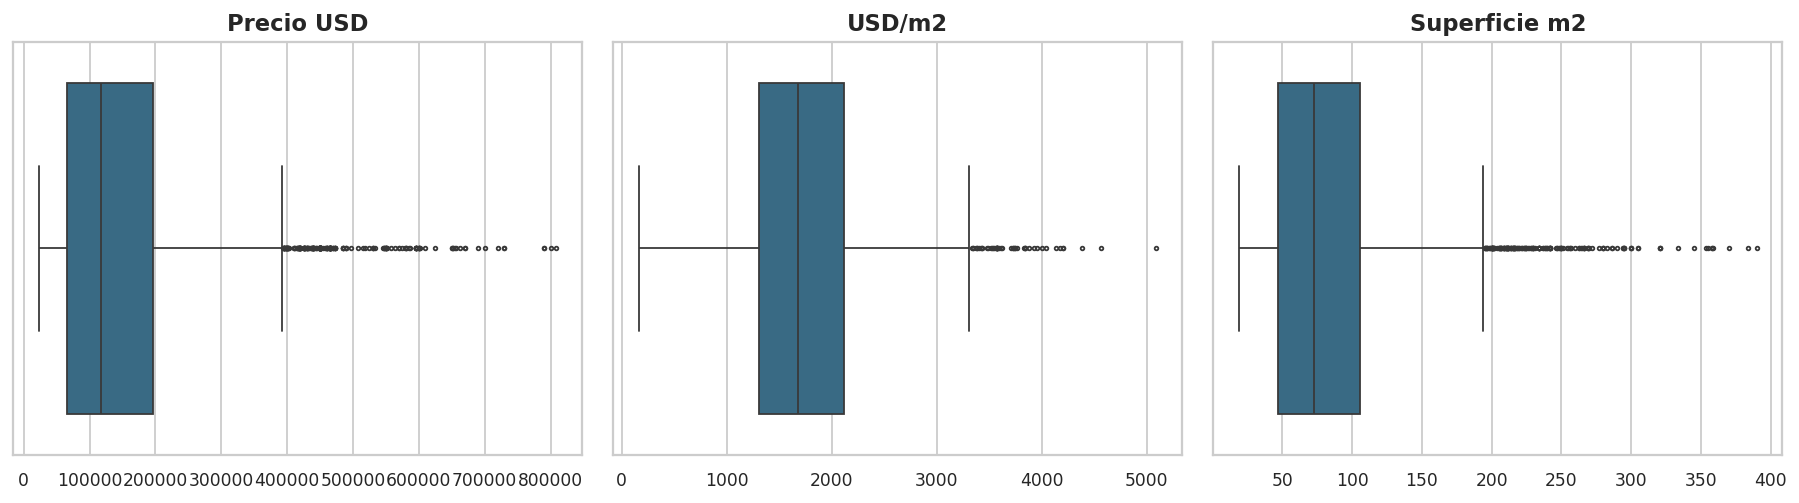

In [17]:
def flags_iqr(s, k=3):
    s = pd.to_numeric(s, errors="coerce"); q1, q3 = s.quantile(.25), s.quantile(.75); iqr = q3-q1
    return int(((s < q1-k*iqr) | (s > q3+k*iqr)).sum())
outl = pd.DataFrame({"variable": ["eda_precio_usd","eda_precio_m2","eda_superficie_total_m2","eda_expensas"]})
outl["outliers (3·IQR)"] = [flags_iqr(df[v]) for v in outl["variable"]]
display(outl.set_index("variable"))
fig, axs = plt.subplots(1, 3, figsize=(14, 4.0))
for ax, c, t in zip(axs, ["eda_precio_usd","eda_precio_m2","eda_superficie_total_m2"], ["Precio USD","USD/m2","Superficie m2"]):
    sns.boxplot(x=num(c), color=PAL, fliersize=2, ax=ax); ax.set(title=t, xlabel="")
plt.show()

La regla 3·IQR marca un número acotado de precios severamente atípicos. Muchos de
ellos corresponden con toda probabilidad a **propiedades legítimamente premium** —unidades grandes,
de categoría o con ubicaciones excepcionales— y no a errores de carga; otros, como el "20 dormitorios"
detectado antes, sí son claramente inconsistentes. Por eso **no eliminamos nada en el EDA**: la
decisión de recorte, winsorización o exclusión se toma en el preprocesamiento, con criterio de
dominio y evaluando su efecto sobre el desempeño del modelo. Marcar sin borrar preserva la
trazabilidad y evita descartar señal real por una regla automática.

## 13. Síntesis y decisiones para el preprocesamiento

El recorrido exploratorio deja un conjunto de decisiones y de hipótesis que estructuran la etapa
siguiente:

- **Target.** La fuerte asimetría del precio (g₁ ≈ 1,74, reducida a ≈ 0,10 con `log1p`) hace del
  **log-precio** una escala candidata para el modelado, con tratamiento explícito del
  *retransformation bias* al reportar en USD.
- **Faltantes.** Distinguir **ausencia estructural** (cocheras, expensas) de faltante genuino; la
  imputación se aprende **dentro del fold** y se acompaña, cuando corresponda, de indicadores de
  "informado".
- **Outliers.** Marcados con 3·IQR; el recorte se decide por dominio en el preprocesamiento, no en
  el EDA. Casos como el "20 dormitorios" se revisan puntualmente.
- **Territorio y espacio.** Hay heterogeneidad de valor por barrio y un gradiente espacial claro
  (noreste más caro): se medirá la autocorrelación (Moran's I) y se estudiará cuánta estructura
  persiste al incorporar covariables de localización.
- **Republicaciones.** El agrupamiento por propiedad/edificio es la base del *group-aware split*
  que evita la fuga de información.
- **Features de texto.** Prevalencias razonables; su aporte se valida fuera de muestra. Renombrar
  `feat_litoral_gas` → `gas_natural` para evitar el equívoco con la empresa distribuidora.
- **Calidad geográfica.** `geo_nivel_calidad` se conserva como variable de auditoría y de
  segmentación del análisis espacial.

Este EDA **no** define folds ni el universo final de modelado: es la base empírica sobre la que se
construye el **preprocesamiento**, próxima etapa del pipeline. Su función es asegurar que ninguna
decisión posterior —transformación del target, tratamiento de faltantes, recorte de outliers o
componente espacial— se tome a ciegas, sino a partir de la evidencia observada en el mercado de
Rosario.

## Referencias

*Fundamentos de los métodos usados en este EDA y de las decisiones metodológicas que anticipa.*
Las referencias de la línea de investigación (Gyger, Tapia, Gutiérrez, Zaki) se citan según el
consolidado bibliográfico de la tesis; **conviene completar autores, año exacto y datos editoriales
en formato APA 7 antes del cierre**, y verificar la edición de las obras clásicas (Tukey, Moran,
LeSage & Pace) tal como ya se advirtió para LeSage.

**Estadística y modelado**

- DeGroot, M. H., & Schervish, M. J. (2012). *Probability and Statistics* (4ª ed.). Pearson. — momentos, distribuciones, inferencia.
- Casella, G., & Berger, R. L. (2002). *Statistical Inference* (2ª ed.). Duxbury. — fundamentos de estimación e inferencia.
- Duan, N. (1983). Smearing estimate: A nonparametric retransformation method. *Journal of the American Statistical Association, 78*(383), 605–610.
- Gauss, C. F. (1809) / Legendre, A. M. (1805). Método de mínimos cuadrados ordinarios.
- Joanes, D. N., & Gill, C. A. (1998). Comparing measures of sample skewness and kurtosis. *Journal of the Royal Statistical Society: Series D, 47*(1), 183–189.
- Kuhn, M., & Johnson, K. (2013). *Applied Predictive Modeling*. Springer.
- Kuhn, M., & Johnson, K. (2019). *Feature Engineering and Selection: A Practical Approach for Predictive Models*. CRC Press.
- Géron, A. (2019). *Hands-On Machine Learning with Scikit-Learn, Keras & TensorFlow* (2ª ed.). O'Reilly.
- Montgomery, D. C., Peck, E. A., & Vining, G. G. (2012). *Introduction to Linear Regression Analysis* (5ª ed.). Wiley.
- Pearson, K. (1895). Note on regression and inheritance in the case of two parents. *Proceedings of the Royal Society of London, 58*, 240–242.
- Rubin, D. B. (1976). Inference and missing data. *Biometrika, 63*(3), 581–592.
- Spearman, C. (1904). The proof and measurement of association between two things. *The American Journal of Psychology, 15*(1), 72–101.
- Tukey, J. W. (1977). *Exploratory Data Analysis*. Addison-Wesley.

**Econometría espacial y precios hedónicos**

- LeSage, J., & Pace, R. K. (2009). *Introduction to Spatial Econometrics*. CRC Press.
- Moran, P. A. P. (1950). Notes on continuous stochastic phenomena. *Biometrika, 37*(1/2), 17–23.
- Rosen, S. (1974). Hedonic prices and implicit markets: Product differentiation in pure competition. *Journal of Political Economy, 82*(1), 34–55.

**Valuación automática (AVM) — línea de investigación**

- Gutiérrez et al. (2026). Antecedente argentino (Buenos Aires): OLS, LASSO y CART sobre avisos web.
- Gyger et al. (2026). *Explainable spatial machine learning for hedonic real estate modeling* (GPBoost; `geolocation_quality`; ablation espacial; retransformation).
- Tapia et al. (2025). LightGBM vs. OLS/SAR, grupos incrementales de variables, SHAP y Moran's I.
- Yazdani, M. (2021). Hedonic pricing y modelos no lineales (ANN, RF, KNN) con target log-precio.
- Zaki et al. (2022). Comparación de modelos hedónicos y de machine learning.

**Fuente de datos geoespaciales**

- Municipalidad de Rosario, Dirección General de Informática. (s.f.). *Distritos Descentralizados* y *Barrios* [Conjuntos de datos]. Portal de Datos Abiertos de la Municipalidad de Rosario. Consultado el 23 de agosto de 2026, de https://datosabiertos.rosario.gob.ar/
  (datasets: [Distritos Descentralizados](https://datosabiertos.rosario.gob.ar/dataset/distritos-descentralizados) y [Barrios](https://datosabiertos.rosario.gob.ar/dataset/barrios)). Cartografía oficial de polígonos en coordenadas geográficas **WGS 84 (EPSG:4326)**, empleada para la validación *point-in-polygon* y la asignación de barrio oficial.